# Does Gemma's base model predict nudge effects?

**Claim E: a second-family *replication* of the narrowed-repertoire account, on `google/gemma-3-4b-pt` (the base
model, "pt") vs `google/gemma-3-4b-it` (the instruction-tuned model, "it").** It is a replication, not a held-out
confirmation: Gemma's iteration-4 push outcomes were already known.

Asked to solve a coding task, the it model almost always writes one **default algorithm** D_u: DFS for grid path
search, Dijkstra for weighted shortest paths, a linear scan for "first and last position of a target" (R6). A
ban-free **activation nudge** adds a random isotropic direction to the residual stream at the task-specification
positions of decoder blocks 11–22. Such nudges move the model off its default on some tasks and not on others.

The *narrowed-repertoire account* says instruction tuning narrows a repertoire that the base model still has. If that
is right, the base model should predict three things:

* **E-A1: which tasks move.** beta_u is the share of non-default catalogue algorithms that the pt model writes on the
  *same token ids*. It should predict E_u, the share of 16 fresh directions (× dose α ∈ {1, 2}) that move the it
  model off D_u without a pass-rate cost. Test: Spearman rho with a one-sided permutation test.
* **E-A2: where they land.** The pt model's runner-up algorithm r_u should be the algorithm the escapes land on.
  Test: hit rate vs chance with an exact Poisson-binomial test, plus the log score of the pt-composition forecast
  q_base vs iteration 4's association and AST-proximity forecasts.
* **Transplant: is the pt state sufficient?** Write the pt model's task-spec states into the it model (λ = 1) on the
  7 base-diverse tasks. Controls: matched-norm random (RND), cross-task (XT) and read-position (RP) transplants, plus
  3 base-collapsed tasks.

**The full run** used one NVIDIA L4 in bf16: 12,290 programs, 2.16 GPU-hours, USD 0.39 of LLM judges. Every program
was labelled with its algorithm by runtime/AST rules plus judges, and run on hidden tests. beta_u, r_u and q_base were
hash-committed before any push sample existed.

**This notebook (CPU only, about a minute)** re-runs the experiment's *CPU stages* on its own *labelled programs*.
`mini_demo_data.json` holds 85 (task, cell) examples with 12,090 labelled rows. The GPU generation, the labeller and
the judges are not re-run: their outputs are those rows. The notebook does four things:

1. rebuilds the predictor table (D_u, beta_u, r_u, q_base) from the twin and pt rows (`src/predictors.py`);
2. re-writes the **frozen analysis code** `analysis_E.py` and checks it against its commit-#0 SHA-256;
3. runs the escape screen, E-A1, E-A2 and the transplant analysis (`src/final_analysis.py`);
4. compares every headline number with the full run and draws figures F1–F6 (`src/figures.py`).

Full-run results, reproduced below:

| test | result |
|---|---|
| E-A1 | **INCONCLUSIVE**. rho(beta, E_u) = 0.42, one-sided p = 0.060, n = 15; 2/3 base-collapsed tasks are immovable |
| E-A2 | **PASS**. The pt runner-up is the push landing in 5/7 events (mean chance 0.30, p = 0.025); q_base beats the association forecast by 1.50 nats/event (Wilcoxon p = 0.023) |
| transplant | **Does not support sufficiency** (2/7). Only T04 (naive → builtin) and R6 (linear scan → binary search) move, both onto the pt runner-up |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (the logger of every original script) and zss (Zhang-Shasha tree edit distance, proximity forecast) -- NOT on Colab, always install
_pip('loguru==0.7.3', 'zss==1.2.0')

# numpy, scipy, pandas, matplotlib -- pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
# import block of method.py, as-is
from __future__ import annotations

import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# imports of the src/ modules whose CPU stages run below (cfg, commit, analysis_E, predictors, prox, final_analysis, figures)
import ast
import collections
import hashlib
import importlib.util
import json
import math
from typing import Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-5/experiment-28/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            remote = json.loads(response.read().decode())
        # An older demo file can sit at this URL until this notebook's data is published: use it only if it is ours.
        if isinstance(remote, dict) and any(ds.get("dataset") == "gemma_unit_cells" for ds in remote.get("datasets", [])):
            return remote
        print("GitHub data is a different (older) demo file, using local mini_demo_data.json")
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(f"{data['datasets'][0]['dataset']}: {len(data['datasets'][0]['examples'])} (task, cell) examples, "
      f"{data['metadata']['n_rows_here']} of the full run's {data['metadata']['n_rows_full_run']} labelled programs")

GitHub data is a different (older) demo file, using local mini_demo_data.json
gemma_unit_cells: 85 (task, cell) examples, 12090 of the full run's 12290 labelled programs


## Configuration

The GPU sample sizes are fixed by the recorded rows: N = 50 it-twin programs per task, 100 + 50 pt programs, 16
directions × 2 doses × N = 10 (confirmation N = 30), N = 50 per transplant arm. What the notebook can scale is the
number of random draws that the frozen statistics use. All of them are seeded, so the original values reproduce the
full run's numbers exactly; smaller values give Monte-Carlo approximations of the p-values and the Hill numbers.
With the original values below, the whole notebook takes about 70 s on 2 CPU cores. About 40 s of that is R6's
proximity forecast: 180 tree edit distances.

In [5]:
N_PERM = 200_000          # E-A1 one-sided permutation draws              (original: 200_000 = THRESH["N_PERM"])
N_BOOT = 10_000           # E-A1 paired task-bootstrap draws per rival    (original: 10_000 = THRESH["N_BOOT"])
SENS_N_PERM = 50_000      # permutation draws of each E-A1 sensitivity    (original: 50_000)
HILL_SUBSAMPLES = 1_000   # subsamples of the rarefied Hill-1 diversity   (original: 1_000)
PROX_MAX_PAIRS = 60       # program pairs per survivor, R6 proximity      (original: 60)
# quick look (about 25 s, approximate p-values): N_PERM = 1_000, N_BOOT = 100, SENS_N_PERM = 1_000,
# HILL_SUBSAMPLES = 10, PROX_MAX_PAIRS = 5

## 1. The pipeline (`method.py`)

`method.py` is the experiment's driver. It runs 26 stage scripts of `src/` in order, each as a subprocess. Alongside
them, a background *label worker* labels every generated program as it arrives: runtime and AST rules on the hidden
tests, with LLM judges for the disputed cases. The stages fall into four groups:

* **GPU generation** (gemma-3-4b-it / -pt, bf16, 24 GB): `it_tests`, `engine_check`, `stage1_it`, `stage1_pt`,
  `ladder`, `stage2`, `stage3_valid`, `stage3`.
* **OpenRouter judges:** `regate`, `rejudge`, `novelty`.
* **Hash-chained commitments:** `commit0`, `commit1`, `amend_M`. They commit the protocol, the analysis code and the
  predictor table *before* any push sample existed.
* **CPU analysis of the labelled rows:** `draft` / `commit1` (predictor table), `analysis` (the frozen analysis),
  `figures`, plus bookkeeping and two independent re-derivations.

The cell below is `method.py` itself; only `ROOT` changes. `main()` is defined but **not called**: a notebook has
neither the `src/` tree nor a GPU. The following sections instead run the CPU stages in-process, with their code
copied from `src/`.

In [6]:
ROOT = Path.cwd()  # notebook: the working directory plays the artifact root (a notebook has no __file__)
PY = sys.executable
STAGES = [
    ("inputs", ["src/stage_inputs.py", "--recheck"]),
    ("it_tests", ["src/gen.py", "it_tests"]),
    ("commit0", ["src/commit0.py"]),
    ("engine_check", ["src/gen.py", "engine_check"]),
    ("engine_eval", ["src/engine_check_eval.py"]),
    ("tests_cpu", ["src/tests_cpu.py"]),
    ("stage1_it", ["src/gen.py", "stage1_it"]),
    ("stage1_pt", ["src/gen.py", "stage1_pt"]),
    ("regate", ["src/regate.py"]),
    ("draft", ["src/predictors.py", "draft"]),
    ("ladder", ["src/gen.py", "ladder"]),
    ("commit1", ["src/predictors.py", "commit1"]),
    ("amend_M", ["src/amend_M.py"]),
    ("stage2", ["src/gen.py", "stage2_pipelined"]),
    ("stage3_valid", ["src/gen.py", "stage3_valid"]),
    ("decide", ["src/transplant_decide.py"]),
    ("stage3", ["src/gen.py", "stage3"]),
    ("rejudge", ["src/rejudge_disputed.py"]),
    ("novelty", ["src/novelty_audit.py"]),
    ("analysis", ["src/final_analysis.py"]),
    ("bookkeeping", ["src/bookkeeping.py"]),
    ("outputs", ["src/outputs.py"]),
    ("rederive", ["audit/rederive.py"]),
    ("rederive2", ["audit/rederive_headlines.py"]),
    ("figures", ["src/figures.py"]),
    ("report", ["src/report.py"]),
]
WAIT_BEFORE = {"engine_eval": ["raw_engine_check.jsonl"], "regate": ["raw_twin.jsonl", "raw_novelty.jsonl",
                                                                     "raw_ptchat.jsonl", "raw_ptplain.jsonl"],
               "decide": ["raw_transplant_valid.jsonl"], "novelty": ["raw_transplant.jsonl", "raw_push.jsonl",
                                                                      "raw_confirm.jsonl"]}

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(exist_ok=True)
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")


def run(cmd: list[str]) -> None:
    t0 = time.time()
    logger.info(f"running {' '.join(cmd)}")
    r = subprocess.run([PY] + cmd, cwd=ROOT)
    if r.returncode != 0:
        raise RuntimeError(f"stage failed ({r.returncode}): {' '.join(cmd)}")
    logger.info(f"done {' '.join(cmd)} in {time.time() - t0:.0f}s")


@logger.catch(reraise=True)
def main() -> None:
    names = [s for s, _ in STAGES]
    start = sys.argv[sys.argv.index("--from") + 1] if "--from" in sys.argv else names[0]
    only = sys.argv[sys.argv.index("--only") + 1] if "--only" in sys.argv else None
    labeller = None
    try:
        for name, cmd in STAGES[names.index(start):]:
            if only and name != only:
                continue
            if name == "engine_check" and labeller is None:
                labeller = subprocess.Popen([PY, "src/label_worker.py"], cwd=ROOT,
                                            stdout=open(ROOT / "logs" / "label_worker.out", "a"),
                                            stderr=subprocess.STDOUT)
                logger.info(f"label worker started (pid {labeller.pid})")
            if name in WAIT_BEFORE and labeller is not None:
                run(["src/wait_labels.py"] + [f for f in WAIT_BEFORE[name] if (ROOT / "data" / f).exists()])
            run(cmd)
    finally:
        if labeller is not None:
            (ROOT / "data" / "STOP_LABELLER").touch()
            labeller.wait(timeout=900)
            (ROOT / "data" / "STOP_LABELLER").unlink(missing_ok=True)


# main() is NOT called here: it launches the stage scripts of src/ as subprocesses, eight of which need gemma-3-4b-it /
# -pt on a 24 GB GPU. The sections below run the CPU stages in-process instead.

In [7]:
# Which stages this notebook re-runs in-process from the labelled rows; the others produced those rows and inputs
IN_NOTEBOOK = {"commit0": "section 3: the frozen analysis code is re-written and checked against this commitment",
               "draft": "section 4: predictor table (src/predictors.py)",
               "commit1": "section 4: predictor table (the GPU-cache parts, massive set M and norms, are loaded)",
               "analysis": "sections 5-9: src/final_analysis.py with the frozen analysis_E.py",
               "figures": "section 10: src/figures.py, F1-F6"}
for name, cmd in STAGES:
    print(f"{name:<13} {' '.join(cmd):<34} {IN_NOTEBOOK.get(name, '-')}")

inputs        src/stage_inputs.py --recheck      -
it_tests      src/gen.py it_tests                -
commit0       src/commit0.py                     section 3: the frozen analysis code is re-written and checked against this commitment
engine_check  src/gen.py engine_check            -
engine_eval   src/engine_check_eval.py           -
tests_cpu     src/tests_cpu.py                   -
stage1_it     src/gen.py stage1_it               -
stage1_pt     src/gen.py stage1_pt               -
regate        src/regate.py                      -
draft         src/predictors.py draft            section 4: predictor table (src/predictors.py)
ladder        src/gen.py ladder                  -
commit1       src/predictors.py commit1          section 4: predictor table (the GPU-cache parts, massive set M and norms, are loaded)
amend_M       src/amend_M.py                     -
stage2        src/gen.py stage2_pipelined        -
stage3_valid  src/gen.py stage3_valid            -
decide        src/tran

## 2. Design constants (`src/cfg.py`) and the labelled rows

There are **15 task units**. Two are path-search tasks from the exp8 suite: T1 (grid path search) and T2 (weighted
shortest path). Thirteen come from the exp11 bench:

| | | | | |
|---|---|---|---|---|
| T03 k-th smallest | T04 substring search | T05 two-sum | T06 find duplicate | T08 Fibonacci |
| T10 connected components | T11 longest increasing subsequence | T13 merge intervals | T14 top-k frequent | |
| R1 non-overlapping intervals | R2 cycle detection | R3 topological order | R6 first/last position | |

Each task has a frozen catalogue of algorithms (*modes*). Every sample sits on a **CRN slot**: a template W1–W5
(neutral, ban-free phrasings) plus a slot k. The sampling uniforms of a slot are identical in every coupled arm, so arms
can be compared program by program. The cell copies the constants of `cfg.py` verbatim; only the paths change, to the
working directory.

In [8]:
# ------------------------------------------------------------------------------------------------ models
IT_ID = "google/gemma-3-4b-it"
IT_REV = "093f9f388b31de276ce2de164bdc2081324b9767"
PT_ID = "google/gemma-3-4b-pt"
PT_REV = "cc012e0a6d0787b4adcc0fa2c4da74402494554d"   # pinned at preflight (huggingface_hub model_info sha)
PT_FALLBACK = ("unsloth/gemma-3-4b-pt", "52aba93981c6ad7712b030eb6dd496ece1d279d6")
MODELS = {"it": (IT_ID, IT_REV), "pt": (PT_ID, PT_REV)}
N_LAYERS = 34
D_MODEL = 2560
BAND = list(range(11, 23))             # middle third of 34 blocks
CAPTURE_BLOCKS = list(range(11, 34))   # realised displacement logged from BAND start to the last block
BOS_ID = 2
EOS_ID = 1
SOT_ID = 105                           # <start_of_turn> (asserted against the tokenizer at load)
EOT_ID = 106                           # <end_of_turn>
STOP_IDS = {"it": (EOS_ID, EOT_ID), "pt": (EOS_ID, EOT_ID, SOT_ID)}
CHAT_HEAD = "<bos><start_of_turn>user\n"
CHAT_TAIL = "<end_of_turn>\n<start_of_turn>model\n"
MAX_NEW_BENCH = 1024
MAX_NEW_PATH = 1536
MAX_NEW_PLAIN = 768
MAX_NEW_EXP23 = 640                    # exp23's cap (engine check only)
STOP_CHECK_EVERY = 16
DECODING = "T1.0_topp1.0_topk-off_inverse-CDF-CRN"
PRECISION = "bf16 (sdpa attention); logits fp32, CDF float64"

# ------------------------------------------------------------------------------------------------ tasks
PATH_TASKS = ("T1", "T2")
BENCH12 = ("T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11")
BENCH_TASKS = BENCH12 + ("R2",)
ALL_TASKS = PATH_TASKS + BENCH_TASKS      # 15 tasks
EXP8_TASK = {"T1": "t1", "T2": "t2"}
# fixed cyclic order of the plan (donor of the cross-task control = next task in this order)
CYCLIC_ORDER = ("T1", "T2", "T03", "T04", "T05", "T06", "T08", "T10", "T11", "T13", "T14", "R1", "R2", "R3", "R6")
# exp23 commit #1 D_g per task: the X whose ban length the frozen twins match (twins are byte-identical to exp23's)
EXP23_TWIN_X = {"T1": "dfs", "T2": "dijkstra", "T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map",
                "T10": "dfs", "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep",
                "R6": "binary_search", "T14": "sort_by_count", "T11": "patience_bisect", "R2": "dfs_parent"}
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral twin) -- protocol W1-W5, verbatim (ban side: length only)
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
PAD_FILLER = " ."
MAX_PAD = 24
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
PLAIN_STDLIB = "Use only the Python standard library."

# ------------------------------------------------------------------------------------------------ design (protocol E)
SLOT_PREFIX = "iter5E"
DIR_SEEDS = tuple(range(52001, 52017))     # 16 never-run isotropic directions
ALPHAS = (1.0, 2.0)
N_TWIN_PER_T = 10                          # twin slots 0-9 per template (N = 50 per task)
N_STAGE1_PER_T = 2                         # escape stage 1: slots 0-1 per template (N = 10 per direction-alpha)
STAGE2_SLOTS = (2, 3, 4, 5)                # confirmation top-up (+20 -> N = 30)
N_PN_PER_T = 10                            # plan noise: 10 per template per alpha (N = 50 per alpha)
N_PT_CHAT_PER_T = 20                       # pt under the it chat template: N = 100 per task
N_PT_PLAIN = 50                            # pt plain completion: N = 50 per task
N_NOVELTY = 30
N_TRANSPLANT_PER_T = 10                    # transplant arms on the twin's slots 0-9 (N = 50)
ESCAPE_EXCESS = 0.20
ESCAPE_PASS_FRAC = 0.80
BINOM_ALPHA = 0.05
P0_FLOOR = 0.01
DEFAULT_SHARE = 0.6
DEFAULT_MIN_CORRECT = 10
BETA_MOVABLE = 0.05
BETA_DIVERSE = 0.2
MIN_CORRECT_BASE = 20
RHO_E = 0.5
P_E = 0.01
IMMOVABLE_FRAC = 0.8
A2_HIT = 0.7
A2_NATS = 0.10
LAMBDA = 1.0
LAMBDA_FALLBACK = 0.5
N_MASSIVE = 5
OTHER_FLOOR = 0.02
B_CRN = 42                                 # fixed batch shape of every coupled single-prompt batch (memory-probed)
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
OPENROUTER_CAP_USD = 1.50
NOT_COUNTED = ("invalid", "disputed")


# ------------------------------------------------------------------------------------------------ paths
ROOT = Path.cwd()                      # notebook: original Path(__file__).resolve().parents[1]
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
for _d in (RESULTS_DIR, FIG_DIR, LOG_DIR, PRED_DIR):
    _d.mkdir(parents=True, exist_ok=True)
# INPUTS / E23 / BENCH / SUITE / DATA_DIR / CACHE_DIR are not needed: what the analysis read there comes from `data`


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())

**The labelled rows.** `mini_demo_data.json` groups the rows of the experiment's `data/labels.jsonl` into one example
per (task, cell). The cells are: `twin` (it, N = 50); `pt_repertoire` (pt under the it chat template N = 100, plus pt
plain completion N = 50); `novelty` (it with a "write a novel algorithm" instruction, N = 30); `escape_population`
(the push stage-1 and confirmation rows); `plan_noise` (a fresh random direction per sample); and `transplant`.

Every row is one generated program. It carries:
* `stage`, `arm`, the CRN `template` / `slot` and the `finish_reason`;
* the algorithm `label`: a catalogue mode, `other` (a different mechanism), `invalid` (no extractable program) or
  `disputed`;
* `passed`, whether the program passes all hidden tests.

Code is kept only for the R6 / T04 programs shown below. The engine-check rows (130) and the λ-validity rows (70)
feed other stages and are left out.

In [9]:
META = data["metadata"]
EXAMPLES = data["datasets"][0]["examples"]
# Flatten the (task, cell) examples back into the rows of data/labels.jsonl that the CPU stages read. File order is
# kept inside every (stage, task, arm), the only order the analysis depends on (e.g. the seeded Hill-1 subsamples).
ROWS = [r for ex in EXAMPLES for r in ex["rows"]]
assert len({r["row_id"] for r in ROWS}) == len(ROWS)

counts = pd.DataFrame([{"task": ex["task"], "cell": ex["cell"], "rows": ex["n_rows"]} for ex in EXAMPLES])
counts = counts.pivot(index="task", columns="cell", values="rows").reindex(list(ALL_TASKS)).fillna(0).astype(int)
display(counts[["twin", "pt_repertoire", "novelty", "escape_population", "plan_noise", "transplant"]])
print(f"{len(ROWS)} labelled programs; rows per stage:", dict(collections.Counter(r["stage"] for r in ROWS)))

cell,twin,pt_repertoire,novelty,escape_population,plan_noise,transplant
task,,,,,,
T1,50,150,30,440,100,0
T2,50,150,30,380,100,50
T03,50,150,30,340,100,210
T04,50,150,30,360,100,210
T06,50,150,30,320,100,210
T05,50,150,30,360,100,210
T10,50,150,30,380,100,210
R1,50,150,30,320,100,50
T08,50,150,30,320,100,0


12090 labelled programs; rows per stage: {'twin': 750, 'ptchat': 1500, 'ptplain': 750, 'novelty': 450, 'push': 6300, 'confirm': 720, 'transplant': 1620}


In [10]:
# One labelled program: the it twin's default on R6 (first and last position of a target in a sorted list)
r0 = next(r for r in ROWS if r["stage"] == "twin" and r["task"] == "R6" and r["label"] == "linear_scan")
print({k: v for k, v in r0.items() if k != "code"})
print(r0["code"])

{'row_id': 'twin|R6|W1|twin|0', 'task': 'R6', 'stage': 'twin', 'arm': 'twin', 'template': 'W1', 'slot': 0, 'label': 'linear_scan', 'passed': True, 'finish_reason': 'stop'}
def solve(nums, target):
    first = -1
    last = -1
    for i, num in enumerate(nums):
        if num == target:
            if first == -1:
                first = i
            last = i
    return [first, last]



## 3. The frozen analysis code (`analysis_E.py`)

Commit #0 hashed the protocol, this analysis module, the input checksums and the hardware before *any* generation.
Commit #1 re-hashed it together with the predictor table before any push sample. `final_analysis.py` then loads the
committed copy from `predictions/analysis_E.py` and calls it unchanged.

The next nine cells write that module part by part with `%%writefile`, unchanged. The first cell overwrites the file
and the others append to it, so **run them in order**. The cell after them loads the module as `final_analysis.py`
does and checks that its SHA-256 equals the committed one.

**3.0 Docstring, imports and the frozen thresholds.** `THRESH` holds every pre-registered number:
* escape: excess ≥ 0.20, pass ≥ 0.8 × twin, binomial α 0.05;
* E-A1: rho ≥ 0.5 with p < 0.01;
* E-A2: hit rate ≥ 0.7 with p < 0.05, and ≥ 0.10 nats;
* beta classes: COLLAPSED < 0.05 ≤ INTERMEDIATE < 0.20 ≤ DIVERSE.

In [11]:
%%writefile predictions/analysis_E.py
#!/usr/bin/env python3
"""FROZEN ANALYSIS for Claim E (hash-committed in commit #0 before any generation; called unchanged afterwards).

Pure functions over labelled rows (dicts with task, stage, arm, template, slot, label, passed) and the commit-#1
predictor table. Label conventions:
  catalogue(u)   = frozen catalogue modes (+ named extended labels promoted by the structural audit, e.g. R6
                   'linear_scan'); 'other', 'invalid', 'disputed' are never catalogue labels.
  off_cat(rows)  = share of ALL attempts whose label is a catalogue survivor (in catalogue, != D_u)   [PRIMARY]
  off_any(rows)  = share of ALL attempts whose label is not D_u / invalid / disputed (exp23's definition)
  off_corr(rows) = share of ALL attempts that PASS the hidden tests with a catalogue-survivor label
  pass(rows)     = share of attempts passing every hidden test
Escape (per unit u, direction s, dose alpha): stage 1 (N=10) off_cat - off_cat(twin) >= 0.20 and pass >= 0.8 x twin
pass; confirmation (N=30 pooled) the same two criteria and binom.sf(k_off - 1, n, max(p0, 0.01)) < 0.05.
E_u(alpha) = confirmed / n_dirs; E_u = mean over alphas (E_u_max = max over alphas, exp23's definition).
"""

from __future__ import annotations

import collections
import itertools
import math
from typing import Any, Callable, Iterable

import numpy as np
from scipy import stats

NOT_CAT = ("other", "invalid", "disputed", None)
THRESH = {"EXCESS": 0.20, "PASS_FRAC": 0.80, "BINOM_ALPHA": 0.05, "P0_FLOOR": 0.01, "RHO_E": 0.5, "P_E": 0.01,
          "P_PARTIAL": 0.05, "IMMOVABLE_FRAC": 0.8, "BETA_MOVABLE": 0.05, "BETA_DIVERSE": 0.2, "RANGE_MIN": 4,
          "RHO_DISCONFIRM": 0.3, "A2_HIT": 0.7, "A2_P": 0.05, "A2_NATS": 0.10, "A2_MIN_EVENTS_WILCOXON": 5,
          "OTHER_FLOOR": 0.02, "N_PERM": 200_000, "N_BOOT": 10_000, "BOOT_CI": 0.90, "HILL_DEPTH": 25,
          "HILL_SUBSAMPLES": 1000, "T_SHARE_OF_BETA": 0.5, "CONTROL_TOL": 0.05}

Writing predictions/analysis_E.py


**3.1 Shares.** `off_cat` (primary) is the share of *all* attempts whose label is a catalogue survivor
(a catalogue mode ≠ D_u). `off_any` is iteration 4's definition: anything but D_u, invalid or disputed. `off_corr`
is the share that also passes the hidden tests.

In [12]:
%%writefile -a predictions/analysis_E.py


# ================================================================================================ shares
def off_cat(rows: list[dict[str, Any]], D: str, cat: Iterable[str]) -> float:
    cat = set(cat)
    if not rows:
        return float("nan")
    return sum(1 for r in rows if r["label"] in cat and r["label"] != D) / len(rows)


def off_any(rows: list[dict[str, Any]], D: str) -> float:
    if not rows:
        return float("nan")
    return sum(1 for r in rows if r["label"] not in (D, "invalid", "disputed")) / len(rows)


def off_corr(rows: list[dict[str, Any]], D: str, cat: Iterable[str]) -> float:
    cat = set(cat)
    if not rows:
        return float("nan")
    return sum(1 for r in rows if r.get("passed") and r["label"] in cat and r["label"] != D) / len(rows)


def pass_rate(rows: list[dict[str, Any]]) -> float:
    return sum(1 for r in rows if r.get("passed")) / len(rows) if rows else float("nan")


def k_off(rows: list[dict[str, Any]], D: str, cat: Iterable[str], kind: str = "cat") -> int:
    cat = set(cat)
    if kind == "cat":
        return sum(1 for r in rows if r["label"] in cat and r["label"] != D)
    if kind == "any":
        return sum(1 for r in rows if r["label"] not in (D, "invalid", "disputed"))
    return sum(1 for r in rows if r.get("passed") and r["label"] in cat and r["label"] != D)


def share_fn(kind: str) -> Callable:
    if kind == "cat":
        return lambda rr, D, cat: off_cat(rr, D, cat)
    if kind == "any":
        return lambda rr, D, cat: off_any(rr, D)
    return lambda rr, D, cat: off_corr(rr, D, cat)

Appending to predictions/analysis_E.py


**3.2 Escape screen.** A direction-dose cell (N = 10) passes stage 1 when two things hold: its off-default share
exceeds the twin's p0 by ≥ 0.20, and its pass rate is ≥ 0.8 × the twin's. A passing cell is topped up to N = 30 and
*confirmed* when both criteria still hold and a one-sided binomial test against p0 gives p < 0.05. E_u is the mean
over α of (confirmed directions / 16). The **landing** is the modal correct off-default catalogue algorithm,
pooled over the confirmed cells.

In [13]:
%%writefile -a predictions/analysis_E.py


# ================================================================================================ escape screen
def escape_unit(twin: list[dict[str, Any]], cells_s1: dict[str, list[dict[str, Any]]],
                cells_conf: dict[str, list[dict[str, Any]]], D: str, cat: list[str], n_dirs: int,
                alphas: tuple[float, ...] = (1.0, 2.0), kind: str = "cat") -> dict[str, Any]:
    """cells_s1[key] = stage-1 rows (N=10) of direction-alpha key 's_a{alpha}'; cells_conf[key] = the confirmation
    rows (+20). Returns stage-1 / confirmation tables, E_u (mean over alphas), E_u_max and per-alpha E."""
    f = share_fn(kind)
    p0, pt = f(twin, D, cat), pass_rate(twin)
    s1, passing = {}, []
    for key, rr in sorted(cells_s1.items()):
        sh, pr = f(rr, D, cat), pass_rate(rr)
        ok = bool(rr) and (sh - p0 >= THRESH["EXCESS"]) and (pr >= THRESH["PASS_FRAC"] * pt)
        s1[key] = {"n": len(rr), "off_share": sh, "excess": sh - p0, "pass": pr, "stage1_pass": ok}
        if ok:
            passing.append(key)
    conf, confirmed = {}, []
    for key in passing:
        rr = cells_s1[key] + cells_conf.get(key, [])
        n = len(rr)
        k = k_off(rr, D, cat, kind)
        sh, pr = (k / n if n else float("nan")), pass_rate(rr)
        pb = float(stats.binom.sf(k - 1, n, max(p0, THRESH["P0_FLOOR"]))) if n else 1.0
        ok = n >= 30 and (sh - p0 >= THRESH["EXCESS"]) and (pr >= THRESH["PASS_FRAC"] * pt) and pb < THRESH["BINOM_ALPHA"]
        conf[key] = {"n": n, "k_off": k, "off_share": sh, "excess": sh - p0, "pass": pr, "binom_p": pb, "confirmed": ok}
        if ok:
            confirmed.append(key)
    E_alpha = {}
    for a in alphas:
        tag = f"_a{int(a)}"
        E_alpha[f"a{int(a)}"] = sum(1 for k in confirmed if k.endswith(tag)) / n_dirs
    E = float(np.mean(list(E_alpha.values()))) if E_alpha else 0.0
    return {"p0": p0, "twin_pass": pt, "n_twin": len(twin), "stage1": s1, "passing": passing, "confirm": conf,
            "confirmed": confirmed, "E_alpha": E_alpha, "E_u": E, "E_u_max": max(E_alpha.values()) if E_alpha else 0.0,
            "movable": E > 0, "n_dirs": n_dirs, "share_kind": kind}


def landing(rows_confirmed: list[dict[str, Any]], D: str, cat: list[str]) -> dict[str, Any]:
    """Modal catalogue label among CORRECT off-default programs pooled over confirmed cells (ties: frozen order)."""
    c = collections.Counter(r["label"] for r in rows_confirmed if r.get("passed") and r["label"] in cat
                            and r["label"] != D)
    if not c:
        return {"defined": False, "landing": None, "composition": {}}
    top = max(c.values())
    lab = next(m for m in cat if c.get(m, 0) == top)
    return {"defined": True, "landing": lab, "composition": dict(c), "n": sum(c.values())}

Appending to predictions/analysis_E.py


**3.3 Diversity.** Correct-only Hill-1 diversity (exp of Shannon entropy) rarefied to depth 25, plus the
Jensen-Shannon divergence and label compositions.

In [14]:
%%writefile -a predictions/analysis_E.py


# ================================================================================================ diversity
def hill1_rarefied(labels: list[str], depth: int = 25, n_sub: int = 1000, seed: int = 0) -> float | None:
    """Hill number of order 1 (exp of Shannon entropy) rarefied to `depth` by subsampling without replacement."""
    if len(labels) < 2:
        return None
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    d = min(depth, len(arr))
    vals = []
    for _ in range(n_sub):
        sub = rng.choice(arr, size=d, replace=False)
        _, cnt = np.unique(sub, return_counts=True)
        p = cnt / cnt.sum()
        vals.append(math.exp(-float((p * np.log(p)).sum())))
    return float(np.mean(vals))


def js_divergence(p: dict[str, float], q: dict[str, float]) -> float:
    keys = sorted(set(p) | set(q))
    P = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    Q = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    if P.sum() == 0 or Q.sum() == 0:
        return float("nan")
    P, Q = P / P.sum(), Q / Q.sum()
    M = 0.5 * (P + Q)

    def kl(a, b):
        m = a > 0
        return float((a[m] * np.log2(a[m] / b[m])).sum())
    return 0.5 * kl(P, M) + 0.5 * kl(Q, M)


def composition(rows: list[dict[str, Any]], correct_only: bool = True) -> dict[str, int]:
    return dict(collections.Counter(r["label"] for r in rows if (r.get("passed") or not correct_only)
                                    and r["label"] not in ("invalid", "disputed")))

Appending to predictions/analysis_E.py


**3.4 Correlation statistics.** Spearman rho; a Monte-Carlo one-sided permutation p with the +1 correction; Kendall
tau-b; partial Spearman; and a paired task bootstrap of rho(beta, E) − rho(rival, E) for each rival predictor.

In [15]:
%%writefile -a predictions/analysis_E.py


# ================================================================================================ correlation stats
def rankdata(x: list[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, dtype=float), method="average")


def spearman(x: list[float], y: list[float]) -> float | None:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3 or np.all(x == x[0]) or np.all(y == y[0]):
        return None
    rx, ry = rankdata(x), rankdata(y)
    return float(np.corrcoef(rx, ry)[0, 1])


def perm_p_one_sided(x: list[float], y: list[float], n_perm: int = THRESH["N_PERM"], seed: int = 0) -> float | None:
    """P(rho_perm >= rho_obs) with the +1 correction, permuting y over units (Monte-Carlo, n_perm draws)."""
    rho = spearman(x, y)
    if rho is None:
        return None
    rx = rankdata(x)
    ry = rankdata(y)
    rx = (rx - rx.mean()) / rx.std()
    ry = (ry - ry.mean()) / ry.std()
    rng = np.random.default_rng(seed)
    n = len(rx)
    hits = 0
    done = 0
    chunk = 20_000
    while done < n_perm:
        m = min(chunk, n_perm - done)
        idx = np.argsort(rng.random((m, n)), axis=1)
        r = (rx[None, :] * ry[idx]).mean(axis=1)
        hits += int((r >= rho - 1e-12).sum())
        done += m
    return (hits + 1) / (n_perm + 1)


def kendall_tau_b(x: list[float], y: list[float]) -> float | None:
    if len(x) < 3:
        return None
    t = stats.kendalltau(x, y, variant="b")
    return None if t.statistic is None or not np.isfinite(t.statistic) else float(t.statistic)


def partial_spearman(x: list[float], y: list[float], Z: list[list[float]]) -> float | None:
    """Spearman partial correlation of x and y given covariates Z (rank-transform, regress out, correlate)."""
    if len(x) < len(Z) + 3:
        return None
    rx, ry = rankdata(x), rankdata(y)
    Zr = np.column_stack([np.ones(len(x))] + [rankdata(z) for z in Z])
    ex = rx - Zr @ np.linalg.lstsq(Zr, rx, rcond=None)[0]
    ey = ry - Zr @ np.linalg.lstsq(Zr, ry, rcond=None)[0]
    if ex.std() == 0 or ey.std() == 0:
        return None
    return float(np.corrcoef(ex, ey)[0, 1])


def boot_rho_diff(x: list[float], r: list[float], y: list[float], n_boot: int = THRESH["N_BOOT"],
                  ci: float = THRESH["BOOT_CI"], seed: int = 0) -> dict[str, Any]:
    """Paired task bootstrap of rho(x, y) - rho(r, y): resample units with replacement; degenerate draws skipped."""
    rng = np.random.default_rng(seed)
    x, r, y = np.asarray(x, float), np.asarray(r, float), np.asarray(y, float)
    n = len(x)
    d = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        a, b = spearman(x[i], y[i]), spearman(r[i], y[i])
        if a is None or b is None:
            continue
        d.append(a - b)
    if not d:
        return {"diff": None, "lo": None, "hi": None, "n_valid": 0, "ahead": False}
    lo, hi = np.quantile(d, [(1 - ci) / 2, 1 - (1 - ci) / 2])
    obs_a, obs_b = spearman(x, y), spearman(r, y)
    diff = None if (obs_a is None or obs_b is None) else obs_a - obs_b
    return {"diff": diff, "lo": float(lo), "hi": float(hi), "n_valid": len(d), "ahead": bool(lo > 0)}

Appending to predictions/analysis_E.py


**3.5 The E-A1 decision rule.**
* **CONFIRMED** requires rho ≥ 0.5 and p < 0.01, ≥ 80% of base-collapsed units immovable, and beta ahead of every
  rival (bootstrap CI > 0).
* **DISCONFIRMED** if rho < 0.3 or most DIVERSE units are immovable.
* **PARTIAL** if rho ≥ 0.5 and p < 0.05.
* **INCONCLUSIVE** otherwise, including when fewer than 4 units have beta ≥ 0.05.

In [16]:
%%writefile -a predictions/analysis_E.py


# ================================================================================================ E-A1
def e_a1(units: list[str], beta: dict[str, float], E: dict[str, float], cls: dict[str, str],
         rivals: dict[str, dict[str, float | None]], rival_sign: dict[str, int], n_perm: int = THRESH["N_PERM"],
         n_boot: int = THRESH["N_BOOT"], seed: int = 0) -> dict[str, Any]:
    """units: defaulted units; beta, E per unit; cls per unit in {COLLAPSED, INTERMEDIATE, DIVERSE}; rivals[name][u]
    raw rival values; rival_sign[name] = +1 if higher predicts MORE movability, -1 if higher predicts less."""
    u = [x for x in units if beta.get(x) is not None and E.get(x) is not None]
    b = [beta[x] for x in u]
    e = [E[x] for x in u]
    rho = spearman(b, e)
    p = perm_p_one_sided(b, e, n_perm=n_perm, seed=seed) if rho is not None else None
    tau = kendall_tau_b(b, e)
    collapsed = [x for x in u if cls[x] == "COLLAPSED"]
    diverse = [x for x in u if cls[x] == "DIVERSE"]
    immov = (sum(1 for x in collapsed if E[x] == 0) / len(collapsed)) if collapsed else None
    div_zero = (sum(1 for x in diverse if E[x] == 0) / len(diverse)) if diverse else None
    n_range = sum(1 for x in u if beta[x] >= THRESH["BETA_MOVABLE"])
    riv = {}
    for name, vals in rivals.items():
        uu = [x for x in u if vals.get(x) is not None and np.isfinite(vals[x])]
        if len(uu) < 4:
            riv[name] = {"n": len(uu), "rho": None, "boot": None, "ahead": False, "note": "too few units"}
            continue
        s = rival_sign.get(name, 1)
        rv = [s * float(vals[x]) for x in uu]
        bt = boot_rho_diff([beta[x] for x in uu], rv, [E[x] for x in uu], n_boot=n_boot, seed=seed)
        riv[name] = {"n": len(uu), "rho": spearman(rv, [E[x] for x in uu]), "boot": bt, "ahead": bt["ahead"],
                     "sign": s}
    ahead_all = all(v["ahead"] for v in riv.values()) if riv else False
    if n_range < THRESH["RANGE_MIN"]:
        verdict = "INCONCLUSIVE"
        why = f"range restriction: {n_range} units with beta >= {THRESH['BETA_MOVABLE']} (< {THRESH['RANGE_MIN']})"
    elif rho is not None and rho >= THRESH["RHO_E"] and p is not None and p < THRESH["P_E"] and immov is not None \
            and immov >= THRESH["IMMOVABLE_FRAC"] and ahead_all:
        verdict, why = "CONFIRMED", "all criteria met"
    elif (rho is not None and rho < THRESH["RHO_DISCONFIRM"]) or (div_zero is not None and div_zero > 0.5):
        verdict = "DISCONFIRMED"
        why = "rho < 0.3" if (rho is not None and rho < THRESH["RHO_DISCONFIRM"]) else "most DIVERSE units immovable"
    elif rho is not None and rho >= THRESH["RHO_E"] and p is not None and p < THRESH["P_PARTIAL"]:
        verdict = "PARTIAL"
        fails = []
        if not (p < THRESH["P_E"]):
            fails.append("p >= 0.01")
        if immov is None or immov < THRESH["IMMOVABLE_FRAC"]:
            fails.append("immovable fraction < 0.8 (or no collapsed units)")
        if not ahead_all:
            fails.append("not ahead of every rival")
        why = "; ".join(fails)
    else:
        verdict, why = "INCONCLUSIVE", "criteria neither met nor disconfirmed"
    return {"units": u, "n": len(u), "beta": {x: beta[x] for x in u}, "E": {x: E[x] for x in u}, "rho": rho,
            "p_one_sided_perm": p, "n_perm": n_perm, "kendall_tau_b": tau, "immovable_frac_collapsed": immov,
            "n_collapsed": len(collapsed), "n_diverse": len(diverse), "diverse_zero_frac": div_zero,
            "n_beta_ge_movable": n_range, "rivals": riv, "ahead_of_every_rival": ahead_all, "verdict": verdict,
            "why": why}

Appending to predictions/analysis_E.py


**3.6 E-A2.** A hit means r_u = landing; the chance of a hit is 1 / (K_u − 1) for K_u catalogue modes. The exact
Poisson-binomial tail gives P(≥ hits). Each forecast's log score is renormalised over the survivors plus an "other"
bin floored at 0.02. **PASS** needs a hit rate ≥ 0.7 with p < 0.05. With ≥ 5 events, q_base must also beat the
association forecast by ≥ 0.10 nats with Wilcoxon p < 0.05.

In [17]:
%%writefile -a predictions/analysis_E.py


# ================================================================================================ E-A2
def poisson_binomial_sf(k: int, ps: list[float]) -> float:
    """P(X >= k) for X = sum of independent Bernoulli(p_i) (exact DP)."""
    dist = np.zeros(len(ps) + 1)
    dist[0] = 1.0
    for p in ps:
        dist[1:] = dist[1:] * (1 - p) + dist[:-1] * p
        dist[0] *= (1 - p)
    return float(dist[k:].sum())


def log_score(q: dict[str, float], ys: list[str], cat_surv: list[str]) -> float | None:
    """Mean log q(y) over outcomes y; q is renormalised over the survivors + an 'other' bin with floor 0.02."""
    if not ys:
        return None
    qq = {m: max(float(q.get(m, 0.0)), 0.0) for m in cat_surv}
    tot = sum(qq.values())
    if tot <= 0:
        qq = {m: 1.0 / len(cat_surv) for m in cat_surv}
        tot = 1.0
    qq = {m: (1 - THRESH["OTHER_FLOOR"]) * v / tot for m, v in qq.items()}
    qq["other"] = THRESH["OTHER_FLOOR"]
    return float(np.mean([math.log(max(qq.get(y, 1e-12), 1e-12)) for y in ys]))


def e_a2(events: list[dict[str, Any]]) -> dict[str, Any]:
    """events: [{unit, r_u, landing, K_u, outcomes: [labels of correct off-default catalogue programs of confirmed
    escapes], survivors, q_base, q_assoc, q_prox}]. Hit = r_u == landing; chance = 1/(K_u - 1)."""
    ev = [e for e in events if e.get("landing") is not None and e.get("r_u") is not None]
    n = len(ev)
    hits = sum(1 for e in ev if e["r_u"] == e["landing"])
    chance = [1.0 / max(e["K_u"] - 1, 1) for e in ev]
    p = poisson_binomial_sf(hits, chance) if n else None
    rate = hits / n if n else None
    mean_chance = float(np.mean(chance)) if chance else None
    passed = bool(n and rate >= THRESH["A2_HIT"] and p is not None and p < THRESH["A2_P"])
    disconf = bool(n and rate <= mean_chance)
    ls = []
    for e in ev:
        ys = e.get("outcomes", [])
        if not ys:
            continue
        rec = {"unit": e["unit"], "n_outcomes": len(ys)}
        for k in ("q_base", "q_assoc", "q_prox"):
            q = e.get(k)
            if not q:
                q = {m: 1.0 / len(e["survivors"]) for m in e["survivors"]}
                rec[f"{k}_defined"] = False
            else:
                rec[f"{k}_defined"] = True
            rec[k] = log_score(q, ys, e["survivors"])
        ls.append(rec)
    out = {"n_events": n, "hits": hits, "hit_rate": rate, "chance": chance, "mean_chance": mean_chance,
           "poisson_binomial_p": p, "pass_hit": passed, "disconfirm_hit": disconf, "log_scores": ls}
    if ls:
        d_assoc = [r["q_base"] - r["q_assoc"] for r in ls]
        d_prox = [r["q_base"] - r["q_prox"] for r in ls]
        out["mean_base_minus_assoc"] = float(np.mean(d_assoc))
        out["mean_base_minus_prox"] = float(np.mean(d_prox))
        if len(ls) >= THRESH["A2_MIN_EVENTS_WILCOXON"]:
            try:
                w = stats.wilcoxon(d_assoc, alternative="greater", zero_method="wilcox")
                out["wilcoxon_p_base_vs_assoc"] = float(w.pvalue)
            except ValueError:
                out["wilcoxon_p_base_vs_assoc"] = None
            out["log_score_test"] = "decisive"
            out["pass_logscore"] = bool(out["mean_base_minus_assoc"] >= THRESH["A2_NATS"]
                                        and (out.get("wilcoxon_p_base_vs_assoc") or 1.0) < 0.05)
        else:
            out["log_score_test"] = (f"descriptive: {len(ls)} matched events < {THRESH['A2_MIN_EVENTS_WILCOXON']} "
                                     "(minimum attainable one-sided Wilcoxon p at n=4 is 0.0625)")
            out["pass_logscore"] = None
        defined = [r for r in ls if r["q_assoc_defined"]]
        if defined:
            out["mean_base_minus_assoc_defined_only"] = float(np.mean([r["q_base"] - r["q_assoc"] for r in defined]))
    if n < 3:
        out["verdict"] = "DESCRIPTIVE (fewer than 3 events)"
    elif passed and out.get("pass_logscore") is not False:
        out["verdict"] = "PASS"
    elif disconf:
        out["verdict"] = "DISCONFIRMED (hit rate at or below chance)"
    else:
        out["verdict"] = "NOT PASSED"
    return out

Appending to predictions/analysis_E.py


**3.7 Transplant.** Each arm is compared with T on the same CRN slots by an exact one-sided McNemar test, with Holm
correction across tasks. A task **supports sufficiency** if all of these hold:
* T stays valid (pass ≥ 0.8 × twin);
* s_T ≥ 0.5 × beta;
* T beats RND, unless RND at the matched norm breaks programs ("norm-confounded");
* T beats XT;
* T lands on r_u.

In [18]:
%%writefile -a predictions/analysis_E.py


# ================================================================================================ transplant
def mcnemar_one_sided(a_succ: dict[Any, bool], b_succ: dict[Any, bool]) -> dict[str, Any]:
    """Exact one-sided McNemar on CRN-paired slots: H1 'a succeeds more than b'. b10 = a only, b01 = b only."""
    keys = sorted(set(a_succ) & set(b_succ))
    b10 = sum(1 for k in keys if a_succ[k] and not b_succ[k])
    b01 = sum(1 for k in keys if b_succ[k] and not a_succ[k])
    n = b10 + b01
    p = float(stats.binom.sf(b10 - 1, n, 0.5)) if n else 1.0
    return {"n_pairs": len(keys), "a_only": b10, "b_only": b01, "p_one_sided": p}


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        adj = min(1.0, (m - i) * p)
        run = max(run, adj)
        out[k] = run
    return out


def transplant_unit(arms: dict[str, list[dict[str, Any]]], twin: list[dict[str, Any]], D: str, cat: list[str],
                    beta: float, r_u: str | None, pt_comp: dict[str, int]) -> dict[str, Any]:
    """arms: {'T', 'RND', 'XT', 'RP'} -> rows on the twin's CRN slots (template, slot)."""
    def succ(rr):
        return {(r["template"], r["slot"]): bool(r.get("passed") and r["label"] in cat and r["label"] != D) for r in rr}

    out: dict[str, Any] = {"twin": {"n": len(twin), "s": off_corr(twin, D, cat), "pass": pass_rate(twin)}}
    for k, rr in arms.items():
        kk = k_off(rr, D, cat, "corr")
        from_ci = _wilson(kk, len(rr))
        out[k] = {"n": len(rr), "s": off_corr(rr, D, cat), "s_ci95": from_ci, "pass": pass_rate(rr),
                  "pass_ratio": (pass_rate(rr) / out["twin"]["pass"]) if out["twin"]["pass"] else None,
                  "composition_correct": composition(rr), "composition_all": composition(rr, correct_only=False)}
    kt = k_off(twin, D, cat, "corr")
    out["twin"]["s_ci95"] = _wilson(kt, len(twin))
    out["twin"]["composition_correct"] = composition(twin)
    if "T" in arms:
        sT = succ(arms["T"])
        for ctl in ("RND", "XT", "RP"):
            if ctl in arms:
                out[f"mcnemar_T_vs_{ctl}"] = mcnemar_one_sided(sT, succ(arms[ctl]))
        out["mcnemar_T_vs_twin"] = mcnemar_one_sided(sT, succ(twin))
        lt = landing(arms["T"], D, cat)
        out["T_landing"] = lt
        out["T_lands_on_r_u"] = bool(lt["defined"] and r_u is not None and lt["landing"] == r_u)
        ptd = {k: v for k, v in pt_comp.items() if k not in ("invalid", "disputed")}
        out["JS_T_pt"] = js_divergence({k: float(v) for k, v in composition(arms["T"]).items()}, ptd)
        out["JS_twin_pt"] = js_divergence({k: float(v) for k, v in composition(twin).items()}, ptd)
        out["T_closer_to_pt"] = (out["JS_T_pt"] < out["JS_twin_pt"]) if (np.isfinite(out["JS_T_pt"])
                                                                         and np.isfinite(out["JS_twin_pt"])) else None
        out["T_valid"] = bool(out["T"]["pass_ratio"] is not None and out["T"]["pass_ratio"] >= THRESH["PASS_FRAC"])
        out["s_T_ge_half_beta"] = bool(out["T"]["s"] >= THRESH["T_SHARE_OF_BETA"] * beta)
        if "RND" in arms:
            out["norm_confounded"] = bool(out["RND"]["pass_ratio"] is not None
                                          and out["RND"]["pass_ratio"] < THRESH["PASS_FRAC"] and out["T_valid"])
    return out


def _wilson(k: int, n: int, z: float = 1.959963984540054) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def transplant_summary(per_unit: dict[str, dict[str, Any]], controls: dict[str, dict[str, Any]]) -> dict[str, Any]:
    """B-style summary: Holm across S_T tasks per comparison; a task 'supports' iff T valid, s_T >= 0.5 beta, beats RND
    (unless norm-confounded) and XT (Holm-adjusted one-sided p < 0.05) and T lands on r_u."""
    out: dict[str, Any] = {}
    for comp in ("RND", "XT", "RP", "twin"):
        ps = {u: v[f"mcnemar_T_vs_{comp}"]["p_one_sided"] for u, v in per_unit.items() if f"mcnemar_T_vs_{comp}" in v}
        out[f"holm_T_vs_{comp}"] = holm(ps) if ps else {}
    support = {}
    for u, v in per_unit.items():
        if "T" not in v:
            continue
        beats_rnd = out["holm_T_vs_RND"].get(u, 1.0) < 0.05
        beats_xt = out["holm_T_vs_XT"].get(u, 1.0) < 0.05
        rnd_ok = beats_rnd or v.get("norm_confounded", False)
        support[u] = {"valid": v["T_valid"], "s_T_ge_half_beta": v["s_T_ge_half_beta"], "beats_RND": beats_rnd,
                      "norm_confounded": v.get("norm_confounded", False), "beats_XT": beats_xt,
                      "lands_on_r_u": v["T_lands_on_r_u"],
                      "supports": bool(v["T_valid"] and v["s_T_ge_half_beta"] and rnd_ok and beats_xt
                                       and v["T_lands_on_r_u"])}
    valid = [u for u, s in support.items() if s["valid"]]
    out["per_unit_support"] = support
    out["n_valid"] = len(valid)
    out["share_supporting_of_valid"] = (sum(1 for u in valid if support[u]["supports"]) / len(valid)) if valid else None
    ctl = {u: {"s_T": v["T"]["s"], "s_twin": v["twin"]["s"],
               "within_tol": abs(v["T"]["s"] - v["twin"]["s"]) <= THRESH["CONTROL_TOL"]} for u, v in controls.items()
           if "T" in v}
    out["collapsed_controls"] = ctl
    out["collapsed_controls_all_within_tol"] = all(c["within_tol"] for c in ctl.values()) if ctl else None
    rp = {u: {"s_RP": v["RP"]["s"], "s_twin": v["twin"]["s"],
              "within_tol": abs(v["RP"]["s"] - v["twin"]["s"]) <= THRESH["CONTROL_TOL"]} for u, v in per_unit.items()
          if "RP" in v}
    out["read_position_site_control"] = rp
    out["rp_all_within_tol"] = all(c["within_tol"] for c in rp.values()) if rp else None
    return out

Appending to predictions/analysis_E.py


**3.8 Self-test.** The CPU test T6 of `src/tests_cpu.py`: a synthetic table with hand-computable answers for
Spearman, the permutation p, the Poisson-binomial tail, McNemar, Holm and Hill-1.

In [19]:
%%writefile -a predictions/analysis_E.py


# ================================================================================================ self test (CPU T6)
def self_test() -> dict[str, Any]:
    """Synthetic table with hand-computable answers."""
    res: dict[str, Any] = {}
    x = [0.0, 0.1, 0.2, 0.3, 0.4]
    y = [0.0, 0.1, 0.3, 0.2, 0.5]
    res["spearman"] = spearman(x, y)                       # ranks 1..5 vs 1,2,4,3,5 -> 1 - 6*2/(5*24) = 0.9
    res["spearman_ok"] = abs(res["spearman"] - 0.9) < 1e-12
    # exact permutation p for n=5: count permutations with rho >= 0.9 -> (1 identity + 4 adjacent swaps) / 120
    exact = sum(1 for perm in itertools.permutations(range(5))
                if spearman(x, [y[i] for i in perm]) >= 0.9 - 1e-12) / 120
    mc = perm_p_one_sided(x, y, n_perm=200_000, seed=1)
    res["perm_p_exact"] = exact
    res["perm_p_mc"] = mc
    res["perm_ok"] = abs(mc - exact) < 0.005
    res["poisson_binomial"] = poisson_binomial_sf(2, [0.5, 0.5, 0.5])   # P(X >= 2) = 0.5
    res["pb_ok"] = abs(res["poisson_binomial"] - 0.5) < 1e-12
    mc2 = mcnemar_one_sided({i: i < 6 for i in range(10)}, {i: i >= 4 for i in range(10)})
    res["mcnemar"] = mc2                                    # a only: 0-3 (4), b only: 6-9 (4) -> p = P(X>=4|8) = 0.636
    res["mcnemar_ok"] = mc2["a_only"] == 4 and mc2["b_only"] == 4 and abs(mc2["p_one_sided"] - 0.63671875) < 1e-9
    res["holm"] = holm({"a": 0.01, "b": 0.04, "c": 0.03})   # 0.03, 0.06, 0.06
    res["holm_ok"] = abs(res["holm"]["a"] - 0.03) < 1e-12 and abs(res["holm"]["c"] - 0.06) < 1e-12 \
        and abs(res["holm"]["b"] - 0.06) < 1e-12
    res["hill1_uniform2"] = hill1_rarefied(["a"] * 50 + ["b"] * 50, depth=100, n_sub=5)
    res["hill_ok"] = abs(res["hill1_uniform2"] - 2.0) < 1e-9
    res["all_ok"] = all(v for k, v in res.items() if k.endswith("_ok"))
    return res

Appending to predictions/analysis_E.py


In [20]:
# final_analysis.py loads the committed copy of the frozen analysis exactly like this
spec = importlib.util.spec_from_file_location("analysis_E_frozen", PRED_DIR / "analysis_E.py")
A = importlib.util.module_from_spec(spec)
spec.loader.exec_module(A)

# ... and commits #0 / #1 recorded its SHA-256 before any generation / before any push sample
ours = sha256_file(PRED_DIR / "analysis_E.py")
print("sha256(predictions/analysis_E.py) =", ours)
for rec in META["commitments_log"]:
    for f, h in rec["files"].items():
        if f.endswith("analysis_E.py"):
            print(f"  {rec['name']:<44} {f:<26} {'MATCH' if h == ours else 'DIFFERENT'}")
assert all(h == ours for rec in META["commitments_log"] for f, h in rec["files"].items() if f.endswith("analysis_E.py"))

sha256(predictions/analysis_E.py) = 4c04c91ad06593aabc4818da8cfa0c0176657fe6e660da319840473ffbea9c0b
  commit0_protocol_analysis_inputs_hardware    predictions/analysis_E.py  MATCH
  commit0_protocol_analysis_inputs_hardware    src/analysis_E.py          MATCH
  commit1_predictors_before_any_push           src/analysis_E.py          MATCH


In [21]:
# src/commit.py: every record's hash = sha256(prev + name + sorted file hashes + utc)
RECREATED = {"predictions/analysis_E.py"}  # notebook: the only committed file re-created byte for byte (section 3)


def verify_chain() -> dict[str, Any]:
    recs = META["commitments_log"]  # original: _records() parses commitments.log
    prev = "0" * 64
    bad = []
    for r in recs:
        body = prev + r["name"] + json.dumps(r["files"], sort_keys=True) + r["utc"]
        if hashlib.sha256(body.encode()).hexdigest() != r["hash"] or r["prev"] != prev:
            bad.append({"name": r["name"], "problem": "chain"})
        for f, h in r["files"].items():
            p = ROOT / f
            if f not in RECREATED:  # notebook: skip the committed files that are not re-created here
                continue
            if not p.exists() or sha256_file(p) != h:
                bad.append({"name": r["name"], "file": f, "problem": "file hash"})
        prev = r["hash"]
    return {"n_records": len(recs), "ok": not bad, "problems": bad}


chain = verify_chain()
print(f"hash chain: {chain['n_records']} records, ok = {chain['ok']}", chain["problems"] or "")
for rec in META["commitments_log"]:
    print(f"  {rec['utc']}  {rec['name']}")
st = A.self_test()  # CPU test T6 of src/tests_cpu.py
print("analysis self-test:", {k: v for k, v in st.items() if k.endswith("_ok")})
assert chain["ok"] and st["all_ok"]

hash chain: 3 records, ok = True 
  2026-10-21T13:10:30.666653Z  commit0_protocol_analysis_inputs_hardware
  2026-10-21T14:41:55.773274Z  commit1_predictors_before_any_push
  2026-10-21T14:45:48.818221Z  commit1b_massive_set_amendment_before_any_transplant_sample
analysis self-test: {'spearman_ok': True, 'perm_ok': True, 'pb_ok': True, 'mcnemar_ok': True, 'holm_ok': True, 'hill_ok': True, 'all_ok': True}


## 4. The predictor table (`src/predictors.py`, stages `draft` and `commit1`)

**The default D_u** is the modal *correct* label of the it twin. It counts only if its share is ≥ 0.6 of ≥ 10 correct
programs, it is a catalogue label and there is no tie.

**The pt repertoire.** beta_u is the share of correct pt programs that use a catalogue survivor. The pt runner-up r_u
is the most common survivor. q_base is the survivor counts + 0.5, normalised: the landing forecast for E-A2.

**The validity gate.** The primary source is pt under the it chat template, provided ≥ 8 defaulted units have ≥ 20
correct pt-chat programs. Here pt-chat is 91% unusable output (10 correct programs in total), so the gate fails and
the source becomes the pre-declared pool of chat + plain completion. Every unit then falls under the **LOW_CORRECT**
rule (< 20 correct programs), so beta and r_u are counted over *valid attempts* instead of correct programs.

**Rivals for E-A1:**
* the twin's modal share;
* the novelty-instruction off-default share (the prompting ceiling);
* the opening margin: a teacher-forced log-probability margin, from the GPU stage `ladder`, loaded here;
* the merit gap: runtime / token ratio of the reference programs, loaded here.

The functions are verbatim; only the row source, the catalogue lookup and the two loaded rivals are adapted.

In [22]:
_LAB: dict[str, Any] = {}


def labels(refresh: bool = False) -> dict[str, dict[str, Any]]:
    if refresh or "x" not in _LAB:
        _LAB["x"] = {r["row_id"]: r for r in ROWS}  # original: read_jsonl(DATA_DIR / "labels.jsonl")
    return _LAB["x"]


def rows(stage: str | None = None, task: str | None = None, arm: str | None = None) -> list[dict[str, Any]]:
    return [r for r in labels().values() if (stage is None or r.get("stage") == stage)
            and (task is None or r.get("task") == task) and (arm is None or r.get("arm") == arm)]


MODES = META["catalogue_modes"]            # original: prompts.modes(task), the frozen bench / exp8-suite catalogue
EXTENDED_LABELS = META["extended_labels"]  # original: from regate_rules import EXTENDED_LABELS


def catalogue(task: str) -> list[str]:
    return list(MODES[task]) + [m for m in EXTENDED_LABELS.get(task, []) if m not in MODES[task]]


def twin_rows(t: str) -> list[dict[str, Any]]:
    return rows("twin", t, "twin")

In [23]:
def default_of(t: str) -> dict[str, Any]:
    cat = catalogue(t)
    tw = twin_rows(t)
    corr = [r for r in tw if r.get("passed") and r["label"] not in ("invalid", "disputed")]
    cnt = collections.Counter(r["label"] for r in corr)
    n_c = len(corr)
    out = {"n_twin": len(tw), "n_correct": n_c, "pass_rate": A.pass_rate(tw), "correct_counts": dict(cnt),
           "attempt_counts": dict(collections.Counter(r["label"] for r in tw))}
    if not cnt:
        return {**out, "D": None, "defaulted": False, "share": None, "reason": "no correct twin program"}
    top = max(cnt.values())
    tops = sorted(m for m, c in cnt.items() if c == top)
    lab = tops[0]
    share = top / n_c
    ok = lab in cat and share >= DEFAULT_SHARE and n_c >= DEFAULT_MIN_CORRECT and len(tops) == 1
    reason = None if ok else ("modal correct label is not a catalogue/extended label" if lab not in cat else
                              f"share {share:.2f} < {DEFAULT_SHARE}" if share < DEFAULT_SHARE else
                              f"{n_c} correct < {DEFAULT_MIN_CORRECT}" if n_c < DEFAULT_MIN_CORRECT else "tie")
    return {**out, "D": lab if ok else None, "modal_correct": lab, "share": share, "defaulted": ok,
            "reason": reason or "ok"}


def base_stats(t: str, D: str | None, prow: list[dict[str, Any]]) -> dict[str, Any]:
    """beta, r_u, q_base, Hill-1 from a set of pt rows."""
    cat = catalogue(t)
    surv = [m for m in cat if m != D]
    corr = [r for r in prow if r.get("passed") and r["label"] != "disputed"]
    n_c = len(corr)
    cc = collections.Counter(r["label"] for r in corr)
    ac = collections.Counter(r["label"] for r in prow)
    low = n_c < MIN_CORRECT_BASE
    if not low:
        beta = sum(cc.get(m, 0) for m in surv) / n_c if n_c else None
        beta_excl_other = (sum(cc.get(m, 0) for m in surv) / max(n_c - cc.get("other", 0), 1)) if n_c else None
        src = "correct"
    else:
        valid = [r for r in prow if r["label"] not in ("disputed", "invalid")]
        beta = (sum(1 for r in valid if r["label"] in surv) / len(valid)) if valid else None
        nv = len([r for r in valid if r["label"] != "other"])
        beta_excl_other = (sum(1 for r in valid if r["label"] in surv) / nv) if nv else None
        src = "attempts (LOW_CORRECT)"
    # r_u: argmax over catalogue minus D of the primary counts (correct counts; LOW_CORRECT: valid-attempt counts),
    # ties -> attempt count -> frozen catalogue order; undefined if the top count is 0
    vc = collections.Counter(r["label"] for r in prow if r["label"] not in ("disputed", "invalid"))
    prim_c = vc if low else cc
    ranked = sorted(surv, key=lambda m: (-prim_c.get(m, 0), -ac.get(m, 0), cat.index(m)))
    r_u = ranked[0] if ranked and prim_c.get(ranked[0], 0) > 0 else None
    q = {m: prim_c.get(m, 0) + 0.5 for m in surv}
    tot = sum(q.values())
    q = {m: v / tot for m, v in q.items()} if tot else {}
    hill = A.hill1_rarefied([r["label"] for r in corr], depth=25, n_sub=HILL_SUBSAMPLES, seed=0) if n_c >= 2 else None
    return {"n_rows": len(prow), "n_correct": n_c, "pass_rate": A.pass_rate(prow), "beta": beta,
            "beta_excl_other": beta_excl_other, "beta_source": src, "low_correct": low, "r_u": r_u,
            "q_base": q, "base_hill1_d25": hill, "hill_flag_lt25": n_c < 25, "correct_counts": dict(cc),
            "attempt_counts": dict(ac),
            "format_failure_rate": (sum(1 for r in prow if r["label"] == "invalid") / len(prow)) if prow else None,
            "finish_reasons": dict(collections.Counter(r.get("finish_reason") for r in prow))}


def cls_of(beta: float | None) -> str | None:
    if beta is None:
        return None
    if beta < BETA_MOVABLE:
        return "COLLAPSED"
    if beta >= BETA_DIVERSE:
        return "DIVERSE"
    return "INTERMEDIATE"

In [24]:
def novelty_off(t: str, D: str | None) -> dict[str, Any]:
    rr = rows("novelty", t, "novelty")
    if not rr or D is None:
        return {"off_cat": None, "pass": A.pass_rate(rr) if rr else None, "n": len(rr)}
    return {"off_cat": A.off_cat(rr, D, catalogue(t)), "off_corr": A.off_corr(rr, D, catalogue(t)),
            "pass": A.pass_rate(rr), "n": len(rr), "composition": A.composition(rr, correct_only=False)}


def merit_gap(t: str, D: str | None, r_u: str | None) -> dict[str, Any]:
    # notebook: the original times the bench reference programs of D and r_u on the hidden tests and counts their
    # Gemma-tokenizer lengths (needs the bench and the tokenizer); the committed values are read from the data instead
    return META["merit_gap"][t]


def donor_map() -> dict[str, str]:
    order = list(CYCLIC_ORDER)
    return {u: order[(i + 1) % len(order)] for i, u in enumerate(order)}

In [25]:
def build_table(ladder: dict[str, Any] | None) -> dict[str, Any]:
    labels(refresh=True)
    units: dict[str, Any] = {}
    for t in ALL_TASKS:
        dflt = default_of(t)
        D = dflt["D"]
        chat = rows("ptchat", t, "pt_chat")
        plain = rows("ptplain", t, "pt_plain")
        units[t] = {"task": t, "catalogue": catalogue(t), "K": len(catalogue(t)), "default": dflt, "D": D,
                    "defaulted": dflt["defaulted"], "pt_chat": base_stats(t, D, chat),
                    "pt_plain": base_stats(t, D, plain), "pt_pooled": base_stats(t, D, chat + plain)}
    defaulted = [t for t in ALL_TASKS if units[t]["defaulted"]]
    n_ok = sum(1 for t in defaulted if units[t]["pt_chat"]["n_correct"] >= MIN_CORRECT_BASE)
    gate = {"n_defaulted": len(defaulted), "n_defaulted_with_ge20_correct_ptchat": n_ok,
            "pass": n_ok >= 8, "primary": "pt_chat" if n_ok >= 8 else "pt_pooled",
            "rule": "fewer than 8 defaulted units with >= 20 correct pt-chat programs -> pooled chat + plain"}
    prim = gate["primary"]
    for t in ALL_TASKS:
        u = units[t]
        b = u[prim]
        u["primary_source"] = prim
        u["beta"], u["r_u"], u["q_base"] = b["beta"], b["r_u"], b["q_base"]
        u["low_correct"] = b["low_correct"]
        u["class"] = cls_of(b["beta"]) if u["defaulted"] else None
        u["predicted_movable"] = (b["beta"] is not None and b["beta"] >= BETA_MOVABLE) if u["defaulted"] else None
        u["base_hill1_d25"] = b["base_hill1_d25"]
        tw = twin_rows(t)
        cnt = collections.Counter(r["label"] for r in tw)
        u["rivals"] = {"twin_modal_share": (cnt.most_common(1)[0][1] / len(tw)) if tw else None,
                       "novelty": novelty_off(t, u["D"])}
        u["rivals"]["novelty_off_cat"] = u["rivals"]["novelty"]["off_cat"]
        lad = (ladder or {}).get(t) or {}
        u["rivals"]["opening_margin"] = lad.get("margin_D_vs_r")
        u["rivals"]["opening_margin_vs_best_survivor"] = lad.get("margin_D_vs_best")
        u["rivals"]["merit_gap"] = merit_gap(t, u["D"], u["r_u"]) if u["defaulted"] else {"defined": False}
        u["chat_vs_plain_agreement"] = {
            "beta_chat": u["pt_chat"]["beta"], "beta_plain": u["pt_plain"]["beta"],
            "r_chat": u["pt_chat"]["r_u"], "r_plain": u["pt_plain"]["r_u"],
            "same_r": u["pt_chat"]["r_u"] == u["pt_plain"]["r_u"]}
    S_T = [t for t in defaulted if (units[t]["beta"] or 0) >= BETA_DIVERSE]
    descriptive = False
    if len(S_T) < 3:
        S_T = [t for t in defaulted if (units[t]["beta"] or 0) >= BETA_MOVABLE]
        descriptive = True
    col = [t for t in defaulted if units[t]["class"] == "COLLAPSED"]
    S_C = sorted(col, key=lambda t: (-units[t]["default"]["pass_rate"], CYCLIC_ORDER.index(t)))[:3]
    return {"units": units, "defaulted": defaulted, "pt_chat_validity_gate": gate, "S_T": S_T, "S_C": S_C,
            "transplant_descriptive": descriptive}

In [26]:
ladder = META["opening_ladder"]  # original: read_json(RESULTS_DIR / "opening_ladder.json"), written by GPU stage 'ladder'
tab = build_table(ladder)
# commit1 adds the transplant set-up; the massive-channel set M and the transplant norms need the 1.4 GB activation
# cache of stage 1 and are not rebuilt (they shaped the transplant itself, whose labelled rows are in the data)
tab["transplant"] = {"S_T": tab["S_T"], "S_C": tab["S_C"], "descriptive": tab["transplant_descriptive"],
                     "donor": donor_map(), "lambda": 1.0,
                     "validity_switch": "lambda 0.5 if T pass < 0.8 x twin on > half of S_T"}
write_json(PRED_DIR / "commit_E1.json", tab)  # in the full run this file is hash-committed as commit #1

committed = META["committed_predictor_table"]
table = pd.DataFrame([{
    "task": t, "D_u (it default)": u["D"], "twin default share": u["default"]["share"],
    "pt correct chat/plain": f'{u["pt_chat"]["n_correct"]}/{u["pt_plain"]["n_correct"]}', "beta_u": u["beta"],
    "class": u["class"], "r_u (pt runner-up)": u["r_u"], "twin modal share": u["rivals"]["twin_modal_share"],
    "novelty off-cat": u["rivals"]["novelty_off_cat"],
    "= commit #1": all(u[k] == committed[t][k] for k in ("D", "catalogue", "beta", "r_u", "q_base", "class"))}
    for t, u in tab["units"].items()]).set_index("task")
display(table.round(3))
print("pt-chat validity gate:", tab["pt_chat_validity_gate"])
print("S_T (transplant tasks, beta >= 0.2):", tab["S_T"], "| S_C (base-collapsed controls):", tab["S_C"])

,D_u (it default),twin default share,pt correct chat/plain,beta_u,class,r_u (pt runner-up),twin modal share,novelty off-cat,= commit #1
task,,,,,,,,,
T1,dfs,0.75,0/0,0.055,INTERMEDIATE,bfs,0.62,0.767,True
T2,dijkstra,1.00,0/0,0.026,COLLAPSED,bf_spfa,1.00,0.200,True
T03,full_sort,1.00,2/12,0.229,DIVERSE,quickselect,1.00,0.667,True
T04,naive,0.88,1/17,0.510,DIVERSE,builtin,0.88,0.700,True
T06,hash_set,1.00,0/14,0.227,DIVERSE,sort_adjacent,1.00,0.000,True
T05,hash_map,1.00,3/10,0.525,DIVERSE,brute_force,1.00,0.000,True
T10,dfs,1.00,0/1,0.278,DIVERSE,bfs,1.00,0.000,True
R1,greedy_end,1.00,0/0,0.024,COLLAPSED,dag_longest_path,1.00,0.000,True
T08,iteration,1.00,1/10,0.096,INTERMEDIATE,fast_doubling,1.00,0.000,True


pt-chat validity gate: {'n_defaulted': 15, 'n_defaulted_with_ge20_correct_ptchat': 0, 'pass': False, 'primary': 'pt_pooled', 'rule': 'fewer than 8 defaulted units with >= 20 correct pt-chat programs -> pooled chat + plain'}
S_T (transplant tasks, beta >= 0.2): ['T03', 'T04', 'T06', 'T05', 'T10', 'R6', 'T11'] | S_C (base-collapsed controls): ['T2', 'T13', 'R1']


## 5. Escape screen and plan noise (`src/final_analysis.py`)

The fresh **push population** has 16 isotropic directions (seeds 52001–52016) × α ∈ {1, 2}. α is measured in
outlier-excluded ban-free units, where α = 1 is 1 unit. Each push displaces the it model's task-spec states in
blocks 11–22. A cell's stage 1 uses the CRN slots 0–1 of every template (N = 10); the confirmation tops it up with
slots 2–5 (N = 30).

`escape_all` applies the frozen screen of 3.2 with three share definitions: `cat` (primary), `any` and `corr`
(sensitivities). **Plan noise** draws a fresh direction for every sample (α 1 / 2, N = 50 each) and serves as the
per-sample noise baseline.

The code is verbatim (only the Hill subsample count comes from the config). The run cell is the first part of
`final_analysis.main()`.

In [27]:
def cells(t: str, stage: str) -> dict[str, list[dict[str, Any]]]:
    out: dict[str, list[dict[str, Any]]] = collections.defaultdict(list)
    for r in rows(stage, t):
        if str(r.get("arm", "")).startswith("esc"):
            s, a = r["arm"][3:].split("_a")
            out[f"{s}_a{a}"].append(r)
    return dict(out)


def escape_all(c1: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for t in ALL_TASKS:
        u = c1["units"][t]
        if not u["defaulted"]:
            out[t] = {"defaulted": False}
            continue
        tw = rows("twin", t, "twin")
        s1, cf = cells(t, "push"), cells(t, "confirm")
        res = {k: A.escape_unit(tw, s1, cf, u["D"], u["catalogue"], len(DIR_SEEDS), ALPHAS, kind=k)
               for k in ("cat", "any", "corr")}
        prim = res["cat"]
        conf_rows = [r for k in prim["confirmed"] for r in s1.get(k, []) + cf.get(k, [])]
        land = A.landing(conf_rows, u["D"], u["catalogue"])
        per_dir = {}
        for s in DIR_SEEDS:
            for a in ALPHAS:
                key = f"{s}_a{int(a)}"
                rr = s1.get(key, [])
                per_dir[key] = {"n": len(rr), "off_cat": A.off_cat(rr, u["D"], u["catalogue"]),
                                "pass": A.pass_rate(rr), "composition": A.composition(rr, correct_only=False),
                                "stage1_pass": prim["stage1"].get(key, {}).get("stage1_pass"),
                                "confirmed": key in prim["confirmed"]}
        out[t] = {"defaulted": True, "D": u["D"], "primary": prim, "sensitivity_off_any": res["any"],
                  "sensitivity_off_corr": res["corr"], "E_u": prim["E_u"], "E_u_max": prim["E_u_max"],
                  "E_u_off_any": res["any"]["E_u"], "E_u_off_corr": res["corr"]["E_u"], "movable": prim["movable"],
                  "landing": land, "per_direction": per_dir,
                  "max_over_directions_off_cat": max((v["off_cat"] for v in per_dir.values() if v["n"]), default=None),
                  "per_direction_off_cat_distribution": sorted(v["off_cat"] for v in per_dir.values() if v["n"])}
    return out


def pn_all(c1: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for t in ALL_TASKS:
        u = c1["units"][t]
        D, cat = u["D"], u["catalogue"]
        tw = rows("twin", t, "twin")
        rec: dict[str, Any] = {"twin": {"n": len(tw), "pass": A.pass_rate(tw),
                                        "hill1_correct_d25": A.hill1_rarefied([r["label"] for r in tw if r.get("passed")], n_sub=HILL_SUBSAMPLES),
                                        "off_corr": A.off_corr(tw, D, cat) if D else None,
                                        "composition_correct": A.composition(tw)}}
        ex = []
        for a in ALPHAS:
            rr = rows("push", t, f"pn_a{int(a)}")
            corr = [r["label"] for r in rr if r.get("passed")]
            rec[f"a{int(a)}"] = {"n": len(rr), "pass": A.pass_rate(rr),
                                 "off_corr": A.off_corr(rr, D, cat) if D else None,
                                 "off_cat": A.off_cat(rr, D, cat) if D else None,
                                 "hill1_correct_d25": A.hill1_rarefied(corr, n_sub=HILL_SUBSAMPLES) if len(corr) >= 2 else None,
                                 "composition_correct": A.composition(rr), "composition_all": A.composition(rr, False)}
            if D and rr:
                ex.append(rec[f"a{int(a)}"]["off_corr"] - rec["twin"]["off_corr"])
        rec["pn_excess"] = max(ex) if ex else None
        out[t] = rec
    return out

In [28]:
setup_logging("final_analysis")
c1 = read_json(PRED_DIR / "commit_E1.json")  # the predictor table written in section 4
esc = escape_all(c1)
write_json(RESULTS_DIR / "escape.json", esc)
pn = pn_all(c1)
write_json(RESULTS_DIR / "pn.json", pn)

display(pd.DataFrame([{
    "task": t, "D_u": esc[t]["D"], "twin off-cat p0": esc[t]["primary"]["p0"],
    "stage-1 cells passing (of 32)": len(esc[t]["primary"]["passing"]), "confirmed": len(esc[t]["primary"]["confirmed"]),
    "E_u": esc[t]["E_u"], "E_u_max": esc[t]["E_u_max"], "landing": esc[t]["landing"].get("landing"),
    "plan-noise excess": pn[t]["pn_excess"]} for t in ALL_TASKS if esc[t]["defaulted"]]).set_index("task").round(3))

,D_u,twin off-cat p0,stage-1 cells passing (of 32),confirmed,E_u,E_u_max,landing,plan-noise excess
task,,,,,,,,
T1,dfs,0.38,6,5,0.156,0.188,bfs,0.02
T2,dijkstra,0.00,3,2,0.062,0.125,bf_spfa,0.04
T03,full_sort,0.00,1,1,0.031,0.062,size_k_heap,0.06
T04,naive,0.12,2,2,0.062,0.125,builtin,0.06
T06,hash_set,0.00,0,0,0.000,0.000,None,0.00
T05,hash_map,0.00,2,2,0.062,0.125,brute_force,0.04
T10,dfs,0.00,3,2,0.062,0.125,union_find,0.14
R1,greedy_end,0.00,0,0,0.000,0.000,None,0.02
T08,iteration,0.00,0,0,0.000,0.000,None,0.00


## 6. E-A1: does beta_u predict *which* tasks move?

Spearman rho(beta_u, E_u) over the defaulted units, with a one-sided permutation p. Each of the five rivals gets a
paired task bootstrap: is beta ahead of it? Two partial correlations control for the catalogue size K and for
iteration 4's forced-"can" count (how many survivors the model *can* write when forced).

The sensitivities re-run the test with other beta sources (chat / plain / pooled / correct-only / re-judged
disputed rows) and other E definitions (`off_any`, `off_corr`, E_u_max, plan-noise excess). They are
descriptive; the frozen verdict uses the primary pair.

In [29]:
def can_count_exp23() -> dict[str, int]:
    """exp23 forced-'can' count: number of non-default catalogue modes with >= 1 correct adherent forced program."""
    out = collections.defaultdict(set)
    for r in META["exp23"]["can_rows"]:  # original: inputs/exp23/data/samples.jsonl (its arm-'can' rows)
        if r.get("arm") == "can" and r.get("passed") and r.get("label") == r.get("mode"):
            out[r["task"]].add(r["mode"])
    return {t: len(out.get(t, set())) for t in ALL_TASKS}


def e_a1_all(c1: dict[str, Any], esc: dict[str, Any], pn: dict[str, Any]) -> dict[str, Any]:
    units = [t for t in ALL_TASKS if c1["units"][t]["defaulted"] and c1["units"][t]["beta"] is not None]
    beta = {t: c1["units"][t]["beta"] for t in units}
    E = {t: esc[t]["E_u"] for t in units}
    cls = {t: c1["units"][t]["class"] for t in units}
    riv = {"twin_modal_share": {t: c1["units"][t]["rivals"]["twin_modal_share"] for t in units},
           "novelty_off_cat": {t: c1["units"][t]["rivals"]["novelty_off_cat"] for t in units},
           "opening_margin": {t: c1["units"][t]["rivals"]["opening_margin"] for t in units},
           "merit_gap_runtime": {t: (c1["units"][t]["rivals"]["merit_gap"] or {}).get("runtime_ratio") for t in units},
           "merit_gap_tokens": {t: (c1["units"][t]["rivals"]["merit_gap"] or {}).get("token_ratio") for t in units}}
    sign = {"twin_modal_share": -1, "novelty_off_cat": 1, "opening_margin": -1, "merit_gap_runtime": -1,
            "merit_gap_tokens": -1}
    main = A.e_a1(units, beta, E, cls, riv, sign, n_perm=N_PERM, n_boot=N_BOOT)  # notebook: sizes from the config
    # checks and sensitivities
    K = {t: c1["units"][t]["K"] for t in units}
    can = can_count_exp23()
    const_E = len({E[t] for t in units}) <= 1
    main["partial_spearman_given_K_and_can"] = None if const_E else A.partial_spearman([beta[t] for t in units], [E[t] for t in units],
                                                                  [[K[t] for t in units], [can[t] for t in units]])
    main["partial_spearman_given_K"] = None if const_E else A.partial_spearman([beta[t] for t in units], [E[t] for t in units],
                                                          [[K[t] for t in units]])
    sens = {}

    def run(name: str, b: dict[str, float | None], e: dict[str, float], uu: list[str] | None = None) -> None:
        uu = [t for t in (uu or units) if b.get(t) is not None and e.get(t) is not None]
        r = A.e_a1(uu, {t: b[t] for t in uu}, {t: e[t] for t in uu},
                   {t: A_cls(b[t]) for t in uu}, {}, {}, n_perm=SENS_N_PERM, n_boot=0)
        sens[name] = {k: r[k] for k in ("n", "rho", "p_one_sided_perm", "kendall_tau_b", "immovable_frac_collapsed",
                                        "n_beta_ge_movable", "verdict")}
    for src in ("pt_chat", "pt_plain", "pt_pooled"):
        run(f"beta_{src}", {t: c1["units"][t][src]["beta"] for t in units}, E)
    run("beta_excl_other", {t: c1["units"][t][c1["units"][t]["primary_source"]]["beta_excl_other"] for t in units}, E)

    def beta_correct_only(t: str) -> float | None:
        u = c1["units"][t]
        cc = u["pt_pooled"]["correct_counts"]
        n = sum(v for k, v in cc.items() if k != "disputed")
        return (sum(cc.get(m, 0) for m in u["catalogue"] if m != u["D"]) / n) if n else None
    run("beta_correct_programs_only_any_n", {t: beta_correct_only(t) for t in units}, E)
    rj = META.get("rejudge_disputed")  # original: results/rejudge_disputed.json (stage 'rejudge', OpenRouter)
    if rj:
        over = {k: v for k, v in rj["labels"].items() if v}

        def beta_rejudged(t: str) -> float | None:
            u = c1["units"][t]
            prow = [dict(r, label=over.get(r["row_id"], r["label"])) for r in
                    rows("ptchat", t, "pt_chat") + rows("ptplain", t, "pt_plain")]
            return base_stats(t, u["D"], prow)["beta"]  # predictors.base_stats (section 4)
        bre = {t: beta_rejudged(t) for t in units}
        run("beta_pooled_with_rejudged_disputed_rows", bre, E)
        sens["beta_pooled_with_rejudged_disputed_rows"]["values"] = bre
    sens["beta_correct_programs_only_any_n"]["values"] = {t: beta_correct_only(t) for t in units}
    run("E_off_any_exp23_definition", beta, {t: esc[t]["E_u_off_any"] for t in units})
    run("E_off_corr", beta, {t: esc[t]["E_u_off_corr"] for t in units})
    run("E_u_max", beta, {t: esc[t]["E_u_max"] for t in units})
    flagged = set(META["regate"].get("flagged_tasks", []))  # original: results/regate.json
    run("without_regate_flagged_tasks", beta, E, [t for t in units if t not in flagged])
    run("secondary_target_pn_excess", beta, {t: pn[t]["pn_excess"] for t in units})
    e23 = META["exp23"]["commit_preban_tasks"]  # original: inputs/exp23/predictions/commit_preban.json (iteration 4)
    run("descriptive_beta_vs_exp23_E_t", beta, {t: e23[t]["E_t"] for t in units})
    agree = {t: {"fresh_movable": E[t] > 0, "iter4_movable": e23[t]["E_t"] > 0} for t in units}
    sens["fresh_vs_iteration4_movability"] = {"per_unit": agree,
                                              "agreement": sum(1 for v in agree.values()
                                                               if v["fresh_movable"] == v["iter4_movable"]) / len(units)}
    main["sensitivities"] = sens
    us = META["exp23"]["unit_sensitivity_per_task"]  # original: inputs/exp23/results/unit_sensitivity.json
    main["dose_check_exp23_ban_over_ox_unit"] = {
        t: float(np.median([v["ratio_ban_over_ox"] for v in us[t].values()])) if t in us else None for t in units}
    dc = {t: v for t, v in main["dose_check_exp23_ban_over_ox_unit"].items() if v is not None}
    main["dose_check_note"] = ("descriptive: median over band blocks of exp23's measured ban displacement in "
                               "outlier-excluded ban-free units (alpha 1 = 1 unit); rho(beta, ratio) = "
                               f"{A.spearman([beta[t] for t in dc], list(dc.values()))}")
    main["flagged_tasks_regate"] = sorted(flagged)
    main["power_note"] = ("n <= 15 units: one-sided critical rho ~0.46 (alpha .05) and ~0.63 (alpha .01) at n=14; a "
                          "true rho of 0.5 has well under 50% power. A replication on seen tasks, never a confirmation.")
    return main


def A_cls(b: float | None) -> str | None:
    if b is None:
        return None
    return "COLLAPSED" if b < A.THRESH["BETA_MOVABLE"] else ("DIVERSE" if b >= A.THRESH["BETA_DIVERSE"] else "INTERMEDIATE")

In [30]:
a1 = e_a1_all(c1, esc, pn)
write_json(RESULTS_DIR / "e_a1.json", a1)
logger.info(f"E-A1: rho={a1['rho']} p={a1['p_one_sided_perm']} immovable={a1['immovable_frac_collapsed']} "
            f"verdict={a1['verdict']} ({a1['why']})")

riv = [{"predictor of E_u": "beta_u (pt repertoire)", "Spearman rho": a1["rho"], "beta_u ahead (90% CI > 0)": "-"}]
riv += [{"predictor of E_u": f"rival {k} (sign {v.get('sign')})", "Spearman rho": v["rho"],
         "beta_u ahead (90% CI > 0)": v["ahead"]} for k, v in a1["rivals"].items()]
display(pd.DataFrame(riv).set_index("predictor of E_u").round(3))
print(f"partial rho | K, can = {a1['partial_spearman_given_K_and_can']:.3f};  partial rho | K = {a1['partial_spearman_given_K']:.3f}")
display(pd.DataFrame({k: {c: v.get(c) for c in ("n", "rho", "p_one_sided_perm", "verdict")}
                      for k, v in a1["sensitivities"].items() if "rho" in v}).T)

16:04:32|INFO   |E-A1: rho=0.4206053577821779 p=0.05957470212648937 immovable=0.6666666666666666 verdict=INCONCLUSIVE (criteria neither met nor disconfirmed)


,Spearman rho,beta_u ahead (90% CI > 0)
predictor of E_u,,
beta_u (pt repertoire),0.421,-
rival twin_modal_share (sign -1),0.668,False
rival novelty_off_cat (sign 1),0.640,False
rival opening_margin (sign -1),0.272,False
rival merit_gap_runtime (sign -1),0.381,False
rival merit_gap_tokens (sign -1),0.409,False


partial rho | K, can = 0.408;  partial rho | K = 0.446


,n,rho,p_one_sided_perm,verdict
beta_pt_chat,15,0.617226,0.0095,PARTIAL
beta_pt_plain,15,0.361606,0.092678,INCONCLUSIVE
beta_pt_pooled,15,0.420605,0.060219,INCONCLUSIVE
beta_excl_other,15,0.388251,0.077058,INCONCLUSIVE
beta_correct_programs_only_any_n,11,0.274004,0.209676,DISCONFIRMED
beta_pooled_with_rejudged_disputed_rows,15,0.388598,0.076398,INCONCLUSIVE
E_off_any_exp23_definition,15,0.420605,0.060219,INCONCLUSIVE
E_off_corr,15,0.519895,0.025799,PARTIAL
E_u_max,15,0.420605,0.060219,INCONCLUSIVE
without_regate_flagged_tasks,14,0.343079,0.112538,INCONCLUSIVE


## 7. E-A2: does the pt runner-up predict *where* the escapes land?

An **event** is a defaulted, movable unit with beta ≥ 0.05 and a defined landing. Its outcomes are the labels of the
correct off-default catalogue programs in the confirmed escape cells. Three forecasts of the outcome distribution
compete:

* **q_base:** the pt composition (committed in commit #1);
* **q_assoc:** iteration 4's association forecast;
* **q_prox:** iteration 4's AST-proximity forecast, the Zhang-Shasha tree edit distance from the forced programs of
  each survivor to the twin's default programs.

On R6, iteration 4 labelled the default `binary_search`; the re-gate added the label `linear_scan`, which is now
R6's default. Because D_u changed, iteration 4's association forecast is undefined for R6 and is scored as uniform.
Its q_prox is recomputed here from the twin programs and the bench's forced programs (`src/prox.py`). With
`PROX_MAX_PAIRS = 60` the recomputation is exact.

In [31]:
# src/prox.py: Zhang-Shasha tree edit distance on identifier-normalised ASTs
SKIP = (ast.expr_context, ast.operator, ast.unaryop, ast.boolop, ast.cmpop)


def _is_doc(n: ast.AST) -> bool:
    return isinstance(n, ast.Expr) and isinstance(getattr(n, "value", None), ast.Constant) and isinstance(n.value.value, str)


def to_tree(code: str):
    from zss import Node

    tree = ast.parse(code)
    names: dict[str, str] = {}

    def nm(x: str) -> str:
        if x not in names:
            names[x] = f"v{len(names) + 1}"
        return names[x]

    def label(n: ast.AST) -> str:
        t = type(n).__name__
        if isinstance(n, (ast.BinOp, ast.AugAssign)):
            t += ":" + type(n.op).__name__
        elif isinstance(n, ast.UnaryOp):
            t += ":" + type(n.op).__name__
        elif isinstance(n, ast.BoolOp):
            t += ":" + type(n.op).__name__
        elif isinstance(n, ast.Compare):
            t += ":" + ",".join(type(o).__name__ for o in n.ops)
        elif isinstance(n, ast.Name):
            t += ":" + nm(n.id)
        elif isinstance(n, ast.arg):
            t += ":" + nm(n.arg)
        elif isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            t += ":" + nm(n.name)
        elif isinstance(n, ast.Attribute):
            t += ":" + nm(n.attr)
        elif isinstance(n, ast.alias):
            t += ":" + nm(n.name) + (":" + nm(n.asname) if n.asname else "")
        elif isinstance(n, ast.Constant):
            v = n.value
            t += ":" + (repr(v) if (type(v) is int and v in (0, 1)) else "C")
        return t

    def build(n: ast.AST):
        node = Node(label(n))
        for c in ast.iter_child_nodes(n):
            if isinstance(c, SKIP) or _is_doc(c):
                continue
            node.addkid(build(c))
        return node

    return build(tree)


def zs_pair(a: str, b: str) -> float | None:
    from zss import simple_distance

    try:
        return float(simple_distance(to_tree(a), to_tree(b)))
    except (SyntaxError, ValueError, RecursionError):
        return None

In [32]:
def prox_recompute(t: str, D: str, surv: list[str]) -> dict[str, float] | None:
    """Zhang-Shasha proximity forecast for a unit whose D changed from exp23's (port of exp23 predictors.proximity)."""
    import random

    # zs_pair: src/prox.py, defined in the cell above

    twin = [r["code"] for r in rows("twin", t, "twin") if r.get("passed") and r["label"] == D and r.get("code")][:20]
    forced: dict[str, list[str]] = collections.defaultdict(list)
    if t in PATH_TASKS:
        return None
    for r in META["bench_forced_programs"].get(t, []):  # original: inputs/exp11/bench/<task_id>/forced_programs.jsonl
        if str(r.get("passed")) == "True" and r.get("label") == r.get("forced_mode") and r.get("code"):
            forced[r["forced_mode"]].append(r["code"])
    if not twin:
        return None
    rng = random.Random(f"prox|{t}")
    med = {}
    for m in surv:
        fs = forced.get(m, [])[:20]
        pairs = [(a, b) for a in fs for b in twin]
        rng.shuffle(pairs)
        ds = [d for d in (zs_pair(a, b) for a, b in pairs[:PROX_MAX_PAIRS]) if d is not None]
        if ds:
            med[m] = float(np.median(ds))
    if not med:
        return None
    scale = float(np.median(list(med.values()))) or 1.0
    z = {m: -med[m] / scale for m in med}
    mx = max(z.values())
    e = {m: np.exp(z[m] - mx) for m in z}
    tot = sum(e.values())
    return {m: float(e.get(m, 0.0) / tot) for m in surv}


def e_a2_all(c1: dict[str, Any], esc: dict[str, Any]) -> dict[str, Any]:
    e23 = META["exp23"]["commit_preban_tasks"]  # original: inputs/exp23/predictions/commit_preban.json (iteration 4)
    prox23 = META["exp23"]["proximity"]  # original: inputs/exp23/results/proximity.json (iteration 4)
    events, notes = [], {}
    for t in ALL_TASKS:
        u = c1["units"][t]
        if not u["defaulted"] or not esc[t].get("movable") or (u["beta"] or 0) < A.THRESH["BETA_MOVABLE"]:
            continue
        land = esc[t]["landing"]
        if not land["defined"]:
            notes[t] = "no defined landing"
            continue
        D, cat = u["D"], u["catalogue"]
        surv = [m for m in cat if m != D]
        s1, cf = cells(t, "push"), cells(t, "confirm")
        conf_rows = [r for k in esc[t]["primary"]["confirmed"] for r in s1.get(k, []) + cf.get(k, [])]
        outcomes = [r["label"] for r in conf_rows if r.get("passed") and r["label"] in surv]
        same_D = e23[t]["D"] == D
        q_assoc = e23[t]["forecasts"]["association"]["distribution"] if (same_D and e23[t]["forecasts"]["association"]["defined"]) else None
        if same_D and prox23.get(f"{t}|{D}", {}).get("defined"):
            q_prox = prox23[f"{t}|{D}"]["distribution"]
        else:
            q_prox = prox_recompute(t, D, surv)
        events.append({"unit": t, "r_u": u["r_u"], "landing": land["landing"], "K_u": len(cat), "outcomes": outcomes,
                       "survivors": surv, "q_base": u["q_base"], "q_assoc": q_assoc, "q_prox": q_prox,
                       "landing_composition": land["composition"], "D_same_as_exp23": same_D})
    res = A.e_a2(events)
    res["events"] = [{k: v for k, v in e.items() if k != "outcomes"} | {"n_outcomes": len(e["outcomes"])} for e in events]
    res["notes"] = notes
    return res

In [33]:
a2 = e_a2_all(c1, esc)
write_json(RESULTS_DIR / "e_a2.json", a2)
logger.info(f"E-A2: events={a2['n_events']} hits={a2['hits']} p={a2['poisson_binomial_p']} verdict={a2['verdict']}")

lsc = {r["unit"]: r for r in a2["log_scores"]}
display(pd.DataFrame([{
    "unit": e["unit"], "K_u": e["K_u"], "D_u": c1["units"][e["unit"]]["D"], "r_u (pt runner-up)": e["r_u"],
    "push landing": e["landing"], "hit": e["r_u"] == e["landing"], "chance": 1 / (e["K_u"] - 1),
    "outcomes": e["n_outcomes"], "log q_base": lsc[e["unit"]]["q_base"], "log q_assoc": lsc[e["unit"]]["q_assoc"],
    "log q_prox": lsc[e["unit"]]["q_prox"]} for e in a2["events"]]).set_index("unit").round(3))
print({k: a2[k] for k in ("n_events", "hits", "hit_rate", "mean_chance", "poisson_binomial_p", "mean_base_minus_assoc",
                          "mean_base_minus_prox", "wilcoxon_p_base_vs_assoc", "verdict")})

16:05:11|INFO   |E-A2: events=7 hits=5 p=0.02518518518518519 verdict=PASS


,K_u,D_u,r_u (pt runner-up),push landing,hit,chance,outcomes,log q_base,log q_assoc,log q_prox
unit,,,,,,,,,,
T1,6,dfs,bfs,bfs,True,0.200,91,-0.388,-0.195,-1.471
T03,6,full_sort,quickselect,size_k_heap,False,0.200,7,-1.707,-3.239,-1.385
T04,6,naive,builtin,builtin,True,0.200,44,-0.093,-3.239,-1.049
T05,4,hash_map,brute_force,brute_force,True,0.333,38,-0.460,-3.156,-0.667
T10,4,dfs,bfs,union_find,False,0.333,20,-0.958,-3.156,-1.157
R6,4,linear_scan,binary_search,binary_search,True,0.333,375,-0.097,-1.119,-1.177
T11,3,patience_bisect,quadratic_dp,quadratic_dp,True,0.500,19,-0.044,-0.116,-0.411


{'n_events': 7, 'hits': 5, 'hit_rate': 0.7142857142857143, 'mean_chance': 0.29999999999999993, 'poisson_binomial_p': 0.02518518518518519, 'mean_base_minus_assoc': 1.4959197083059959, 'mean_base_minus_prox': 0.5098819078414555, 'wilcoxon_p_base_vs_assoc': 0.0234375, 'verdict': 'PASS'}


## 8. The pt → it transplant: is the base model's state sufficient?

On the 7 base-diverse tasks S_T (beta ≥ 0.2), arm **T** interpolates the it model's task-spec states towards the
pt model's states on the same token ids, during the prefill at every block 11–22: h ← h + λ (h_pt − h). With
λ = 1 this is a replacement. Every arm runs on the twin's CRN slots 0–9 per template (N = 50). The controls split
the transplant displacement d = h_pt − h_it into its part on the massive channels M* (d_M) and the rest (d_ox):

* **RND:** keeps the massive-channel move d_M, but moves the other channels by ‖d_ox‖ along a random isotropic
  direction;
* **XT:** the same, along the mean displacement of a donor task (the next task in a fixed cyclic order);
* **RP:** the transplant at the read position (the last prompt token) instead of the task-spec positions.

The 3 base-collapsed tasks S_C get T only: there, T should *not* move anything.

`s` is the share of attempts that pass the hidden tests with a catalogue-survivor label.

In [34]:
def transplant_all(c1: dict[str, Any]) -> dict[str, Any]:
    tr = c1["transplant"]
    lam = META.get("transplant_lambda") or {"lambda": None, "status": "not run"}  # original: results/transplant_lambda.json
    per, ctl = {}, {}
    for u in tr["S_T"] + tr["S_C"]:
        un = c1["units"][u]
        D, cat = un["D"], un["catalogue"]
        tw = [r for r in rows("twin", u, "twin")]
        arms = {k: rows("transplant", u, k) for k in ("T", "RND", "XT", "RP")}
        arms = {k: v for k, v in arms.items() if v}
        if not arms:
            continue
        pt_rows = rows("ptchat", u, "pt_chat") + rows("ptplain", u, "pt_plain")
        pt_comp = A.composition(pt_rows)
        res = A.transplant_unit(arms, tw, D, cat, un["beta"] or 0.0, un["r_u"], pt_comp)
        res["beta"], res["r_u"], res["D"] = un["beta"], un["r_u"], D
        disp = [r["realised_disp"]["S_mean_band"] for r in arms.get("T", []) if r.get("realised_disp")]
        res["realised_disp_T_S_mean_band_median"] = float(np.median(disp)) if disp else None
        for k in ("RND", "XT", "RP"):
            dd = [r["realised_disp"]["S_mean_band"] for r in arms.get(k, []) if r.get("realised_disp")]
            res[f"realised_disp_{k}_S_mean_band_median"] = float(np.median(dd)) if dd else None
        (per if u in tr["S_T"] else ctl)[u] = res
    summ = A.transplant_summary(per, ctl)
    return {"lambda": lam, "S_T": tr["S_T"], "S_C": tr["S_C"], "descriptive": tr["descriptive"], "per_unit": per,
            "controls": ctl, "summary": summ, "norms": META.get("transplant_norms")}  # original: results/transplant_norms.json

In [35]:
tp = transplant_all(c1)
write_json(RESULTS_DIR / "transplant.json", tp)
logger.info(f"transplant summary: {tp['summary'].get('share_supporting_of_valid')} valid={tp['summary'].get('n_valid')}")

sup = tp["summary"]["per_unit_support"]
display(pd.DataFrame([{
    "task": u, "beta_u": v["beta"], "r_u": v["r_u"], **{f"s {k}": v[k]["s"] for k in ("twin", "T", "RND", "XT", "RP") if k in v},
    "pass T/twin": v["T"]["pass_ratio"], "pass RND/twin": v.get("RND", {}).get("pass_ratio"),
    "pass XT/twin": v.get("XT", {}).get("pass_ratio"),
    "T landing": v["T_landing"].get("landing"), "norm-confounded": v.get("norm_confounded"), "supports": sup[u]["supports"]}
    for u, v in tp["per_unit"].items()]).set_index("task").round(2))
print("base-collapsed controls (T vs twin):", tp["summary"]["collapsed_controls"])

16:05:11|INFO   |transplant summary: 0.2857142857142857 valid=7


,beta_u,r_u,s twin,s T,s RND,s XT,s RP,pass T/twin,pass RND/twin,pass XT/twin,T landing,norm-confounded,supports
task,,,,,,,,,,,,,
T03,0.23,quickselect,0.00,0.00,0.02,0.0,0.0,1.00,0.44,0.08,None,True,False
T04,0.51,builtin,0.12,0.80,0.04,0.0,0.1,1.00,0.16,0.00,builtin,True,True
T06,0.23,sort_adjacent,0.00,0.00,0.00,0.0,0.0,0.98,0.40,0.18,None,True,False
T05,0.52,brute_force,0.00,0.00,0.04,0.0,0.0,1.00,0.34,0.14,None,True,False
T10,0.28,bfs,0.00,0.00,0.02,0.0,0.0,1.00,0.50,0.00,None,True,False
R6,0.40,binary_search,0.08,0.78,0.06,0.0,0.1,1.00,0.20,0.00,binary_search,True,True
T11,0.41,quadratic_dp,0.00,0.02,0.16,0.0,0.0,1.00,0.48,0.22,quadratic_dp,True,False


base-collapsed controls (T vs twin): {'T2': {'s_T': 0.0, 's_twin': 0.0, 'within_tol': True}, 'T13': {'s_T': 0.0, 's_twin': 0.0, 'within_tol': True}, 'R1': {'s_T': 0.0, 's_twin': 0.0, 'within_tol': True}}


In [36]:
# What moved: the it twin's default vs the transplanted program on the SAME CRN slot, next to the pt model's own
# runner-up program (pt plain completion / chat template) for the two tasks that support sufficiency
for t in ("T04", "R6"):
    u = c1["units"][t]
    twin_by_slot = {(r["template"], r["slot"]): r for r in rows("twin", t, "twin")}
    r_T = next(r for r in rows("transplant", t, "T") if r["passed"] and r["label"] == u["r_u"]
               and twin_by_slot[(r["template"], r["slot"])]["label"] == u["D"])
    r_tw = twin_by_slot[(r_T["template"], r_T["slot"])]
    r_pt = next(r for r in rows("ptplain", t, "pt_plain") + rows("ptchat", t, "pt_chat") if r.get("code"))
    print(f"=================== {t}: D_u = {u['D']}, pt runner-up r_u = {u['r_u']}; CRN slot {r_T['template']}/{r_T['slot']}")
    print(f"--- it twin (label {r_tw['label']}, passed {r_tw['passed']}):\n{r_tw['code']}\n")
    print(f"--- pt->it transplant T (label {r_T['label']}, passed {r_T['passed']}):\n{r_T['code']}\n")
    print(f"--- pt itself, {r_pt['arm']} (label {r_pt['label']}, passed {r_pt['passed']}):\n{r_pt['code'][:1200]}\n")

=================== T04: D_u = naive, pt runner-up r_u = builtin; CRN slot W1/0
--- it twin (label naive, passed True):
def solve(haystack, needle):
    if len(needle) > len(haystack):
        return -1
    
    for i in range(len(haystack) - len(needle) + 1):
        if haystack[i:i + len(needle)] == needle:
            return i
    
    return -1


--- pt->it transplant T (label builtin, passed True):
def solve(haystack, needle):
    """
    Finds the index of the first occurrence of needle in haystack.

    Args:
        haystack: The string to search within.
        needle: The string to search for.

    Returns:
        The index of the first occurrence of needle in haystack, or -1 if not found.
    """
    try:
        return haystack.index(needle)
    except ValueError:
        return -1


--- pt itself, pt_plain (label builtin, passed True):
def solve(haystack, needle):
    a = haystack.find(needle)
    return a


=================== R6: D_u = linear_scan, pt runner-up r_u = bi

## 9. Verdicts (the end of `final_analysis.main()`)

The frozen verdicts of the three tests, plus the novelty audit, which is loaded. Its finding: none of the 56 correct
"other" programs is a genuinely novel algorithm (rule-of-three bound 0.054).

In [37]:
na = META.get("novelty_audit", {})  # original: results/novelty_audit.json (stage 'novelty', OpenRouter judges)
summ = tp["summary"]
lam = tp["lambda"].get("lambda")
if not tp["per_unit"]:
    tverd = "NOT RUN"
elif summ.get("n_valid", 0) == 0:
    tverd = "UNTESTED (broken test: T fails the validity criterion on every S_T task)"
elif tp["descriptive"]:
    tverd = "DESCRIPTIVE (|S_T| < 3 with beta >= 0.2)"
else:
    share = summ.get("share_supporting_of_valid")
    tverd = "SUPPORTS SUFFICIENCY" if (share is not None and share >= 0.5) else "DOES NOT SUPPORT SUFFICIENCY"
verdicts = {"E_A1": {"verdict": a1["verdict"], "why": a1["why"], "rho": a1["rho"], "p": a1["p_one_sided_perm"],
                     "n_units": a1["n"], "immovable_frac_collapsed": a1["immovable_frac_collapsed"]},
            "E_A2": {"verdict": a2["verdict"], "n_events": a2["n_events"], "hits": a2["hits"],
                     "p": a2["poisson_binomial_p"], "log_score_test": a2.get("log_score_test")},
            "transplant": {"verdict": tverd, "lambda": lam, "S_T": tp["S_T"], "S_C": tp["S_C"],
                           "share_supporting_of_valid": summ.get("share_supporting_of_valid"),
                           "collapsed_controls_within_tol": summ.get("collapsed_controls_all_within_tol"),
                           "rp_within_tol": summ.get("rp_all_within_tol")},
            "novelty": {"n_correct_other": na.get("n_correct_other"), "novel_count": na.get("novel_count"),
                        "rule_of_three_upper_95": na.get("rule_of_three_upper_95")},
            "status": "REPLICATION on seen tasks (never a confirmation); Holm across the secondary family is "
                      "applied by the evaluation step"}
write_json(RESULTS_DIR / "verdicts.json", verdicts)
logger.info(f"verdicts: {verdicts}")
for t in ALL_TASKS:
    if esc[t].get("defaulted"):
        logger.info(f"{t}: D={esc[t]['D']} E={esc[t]['E_u']:.3f} Emax={esc[t]['E_u_max']:.3f} "
                    f"beta={c1['units'][t]['beta']} landing={esc[t]['landing'].get('landing')} r={c1['units'][t]['r_u']}")

16:05:12|INFO   |verdicts: {'E_A1': {'verdict': 'INCONCLUSIVE', 'why': 'criteria neither met nor disconfirmed', 'rho': 0.4206053577821779, 'p': 0.05957470212648937, 'n_units': 15, 'immovable_frac_collapsed': 0.6666666666666666}, 'E_A2': {'verdict': 'PASS', 'n_events': 7, 'hits': 5, 'p': 0.02518518518518519, 'log_score_test': 'decisive'}, 'transplant': {'verdict': 'DOES NOT SUPPORT SUFFICIENCY', 'lambda': 1.0, 'S_T': ['T03', 'T04', 'T06', 'T05', 'T10', 'R6', 'T11'], 'S_C': ['T2', 'T13', 'R1'], 'share_supporting_of_valid': 0.2857142857142857, 'collapsed_controls_within_tol': True, 'rp_within_tol': True}, 'novelty': {'n_correct_other': 56, 'novel_count': 0, 'rule_of_three_upper_95': 0.05357142857142857}, 'status': 'REPLICATION on seen tasks (never a confirmation); Holm across the secondary family is applied by the evaluation step'}


16:05:12|INFO   |T1: D=dfs E=0.156 Emax=0.188 beta=0.0547945205479452 landing=bfs r=bfs


16:05:12|INFO   |T2: D=dijkstra E=0.062 Emax=0.125 beta=0.02564102564102564 landing=bf_spfa r=bf_spfa


16:05:12|INFO   |T03: D=full_sort E=0.031 Emax=0.062 beta=0.22916666666666666 landing=size_k_heap r=quickselect


16:05:12|INFO   |T04: D=naive E=0.062 Emax=0.125 beta=0.5098039215686274 landing=builtin r=builtin


...

16:05:12|INFO   |T13: D=sort_sweep E=0.000 Emax=0.000 beta=0.038461538461538464 landing=None r=union_find


16:05:12|INFO   |R6: D=linear_scan E=0.531 Emax=0.688 beta=0.4 landing=binary_search r=binary_search


16:05:12|INFO   |T14: D=sort_by_count E=0.000 Emax=0.000 beta=0.11904761904761904 landing=None r=quickselect_counts


16:05:12|INFO   |T11: D=patience_bisect E=0.031 Emax=0.062 beta=0.40816326530612246 landing=quadratic_dp r=quadratic_dp


16:05:12|INFO   |R2: D=dfs_parent E=0.000 Emax=0.000 beta=0.1111111111111111 landing=None r=edge_count


## 10. Results: this notebook vs the full run

Every quantity below is recomputed from the labelled rows. p-values from permutations, Hill numbers and R6's
proximity forecast are seeded Monte-Carlo or subsampled quantities. They equal the full run's values only with the
original sizes in the configuration cell; everything else must match exactly.

In [38]:
def same(a, b):
    if isinstance(a, float) or isinstance(b, float):
        return a is not None and b is not None and abs(a - b) < 1e-9
    return a == b


ref = META["reference_full_run"]
verd = read_json(RESULTS_DIR / "verdicts.json")
checks = [
    ("predictor table = commit #1 (tasks)", int(table["= commit #1"].sum()), 15),
    ("E_u equal to the full run (tasks)", sum(same(esc[t]["E_u"], ref["escape_E_u"][t]) for t in ALL_TASKS), 15),
    ("E-A1 Spearman rho(beta_u, E_u)", a1["rho"], ref["e_a1"]["rho"]),
    ("E-A1 one-sided permutation p", a1["p_one_sided_perm"], ref["e_a1"]["p_one_sided_perm"]),
    ("E-A1 Kendall tau-b", a1["kendall_tau_b"], ref["e_a1"]["kendall_tau_b"]),
    ("E-A1 immovable share of collapsed units", a1["immovable_frac_collapsed"], ref["e_a1"]["immovable_frac_collapsed"]),
    ("E-A1 partial rho given K and can", a1["partial_spearman_given_K_and_can"], ref["e_a1"]["partial_spearman_given_K_and_can"]),
    ("E-A1 beta ahead of every rival", a1["ahead_of_every_rival"], ref["e_a1"]["ahead_of_every_rival"]),
    ("E-A1 verdict", a1["verdict"], ref["e_a1"]["verdict"]),
    ("E-A2 events", a2["n_events"], ref["e_a2"]["n_events"]),
    ("E-A2 hits (r_u = landing)", a2["hits"], ref["e_a2"]["hits"]),
    ("E-A2 mean chance", a2["mean_chance"], ref["e_a2"]["mean_chance"]),
    ("E-A2 Poisson-binomial p", a2["poisson_binomial_p"], ref["e_a2"]["poisson_binomial_p"]),
    ("E-A2 log q_base - log q_assoc (nats/event)", a2["mean_base_minus_assoc"], ref["e_a2"]["mean_base_minus_assoc"]),
    ("E-A2 log q_base - log q_prox (nats/event)", a2["mean_base_minus_prox"], ref["e_a2"]["mean_base_minus_prox"]),
    ("E-A2 Wilcoxon p (base vs association)", a2["wilcoxon_p_base_vs_assoc"], ref["e_a2"]["wilcoxon_p_base_vs_assoc"]),
    ("E-A2 verdict", a2["verdict"], ref["e_a2"]["verdict"]),
    ("transplant: valid S_T tasks", tp["summary"]["n_valid"], ref["transplant_summary"]["n_valid"]),
    ("transplant: share supporting sufficiency", tp["summary"]["share_supporting_of_valid"], ref["transplant_summary"]["share_supporting_of_valid"]),
    ("transplant: collapsed controls within tolerance", tp["summary"]["collapsed_controls_all_within_tol"], ref["transplant_summary"]["collapsed_controls_all_within_tol"]),
    ("transplant: RP control within tolerance", tp["summary"]["rp_all_within_tol"], ref["transplant_summary"]["rp_all_within_tol"]),
    ("transplant verdict", verd["transplant"]["verdict"], ref["verdicts"]["transplant"]["verdict"]),
]
cmp = pd.DataFrame([{"quantity": q, "this notebook": a, "full run": b, "equal": same(a, b)} for q, a, b in checks])
display(cmp.set_index("quantity"))
print(f"{int(cmp['equal'].sum())}/{len(cmp)} equal  (config: N_PERM={N_PERM}, N_BOOT={N_BOOT}, SENS_N_PERM={SENS_N_PERM}, "
      f"HILL_SUBSAMPLES={HILL_SUBSAMPLES}, PROX_MAX_PAIRS={PROX_MAX_PAIRS})")

,this notebook,full run,equal
quantity,,,
predictor table = commit #1 (tasks),15,15,True
E_u equal to the full run (tasks),15,15,True
"E-A1 Spearman rho(beta_u, E_u)",0.420605,0.420605,True
E-A1 one-sided permutation p,0.059575,0.059575,True
E-A1 Kendall tau-b,0.367007,0.367007,True
E-A1 immovable share of collapsed units,0.666667,0.666667,True
E-A1 partial rho given K and can,0.407674,0.407674,True
E-A1 beta ahead of every rival,False,False,True
E-A1 verdict,INCONCLUSIVE,INCONCLUSIVE,True


22/22 equal  (config: N_PERM=200000, N_BOOT=10000, SENS_N_PERM=50000, HILL_SUBSAMPLES=1000, PROX_MAX_PAIRS=60)


### Figures (`src/figures.py`)

* **F1:** beta_u vs E_u.
* **F2:** per-task compositions of pt, the it twin and the confirmed push landings.
* **F3:** stage-1 off-default share of all 16 × 2 direction-dose cells (* = confirmed).
* **F4:** transplant arms with 95% Wilson intervals; the dashed line is beta.
* **F5:** transplant displacement per block, in ban-free units.
* **F6:** re-gate labels vs adjudication.

The figure code is `figures.py` with two changes: the figures are shown inline rather than closed, and the
house-style helpers of the authoring environment are absent, so the plain fallback the module already contains is
used. As in `figures.py`, the inputs are read back from the `results/*.json` files the analysis wrote.

In [39]:
SK = Path(__import__("os").environ.get("AII_DATA_FIG_GEN", "aii-data-fig-gen/scripts"))  # skill scripts dir
sys.path.insert(0, str(SK))
import matplotlib  # noqa: E402

# matplotlib.use("Agg")  # notebook: keep the inline backend so that the figures are displayed
import matplotlib.pyplot as plt  # noqa: E402

try:
    from chart_geometry import fit_point_labels  # noqa: E402
    from chart_style import (PALETTE, apply_house_style, clear_legends_of_data, fit_legends, fit_tick_labels,  # noqa: E402
                             fit_titles, literal, place_legend, place_point_label)
    HOUSE = True
except ImportError:  # the skill scripts are not part of the published repository
    HOUSE = False
    PALETTE = ["#0173B2", "#DE8F05", "#029E73", "#D55E00", "#CC78BC", "#CA9161", "#FBAFE4", "#949494"]


def style() -> None:
    if HOUSE:
        apply_house_style()


def finish(fig, name: str) -> None:
    if HOUSE:
        try:
            fit_legends(fig)
            clear_legends_of_data(fig)
            fit_tick_labels(fig)
            fit_titles(fig)
            clear_legends_of_data(fig)
            fit_point_labels(fig)
        except Exception as e:  # noqa: BLE001 - layout helpers are best effort
            print(f"layout helper failed on {name}: {e}")
    fig.savefig(FIG_DIR / f"{name}.pdf")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200)
    plt.show()  # notebook: display inline (original: plt.close(fig))


def legend(ax, loc="best"):
    if HOUSE:
        place_legend(ax, loc=loc)
    else:
        ax.legend(loc=loc, fontsize=8)


def f1(c1, a1, esc) -> None:
    style()
    fig, ax = plt.subplots(figsize=(6.5, 4.2), layout="constrained")
    units = a1["units"]
    x = [a1["beta"][t] for t in units]
    y = [a1["E"][t] for t in units]
    cls = [c1["units"][t]["class"] for t in units]
    col = {"COLLAPSED": PALETTE[0], "INTERMEDIATE": PALETTE[1], "DIVERSE": PALETTE[2]}
    for c in ("COLLAPSED", "INTERMEDIATE", "DIVERSE"):
        xi = [a for a, k in zip(x, cls) if k == c]
        yi = [b for b, k in zip(y, cls) if k == c]
        if xi:
            ax.scatter(xi, yi, s=40, color=col[c], label=c.lower(), zorder=3)
    for t, a, b in zip(units, x, y):
        if HOUSE:
            place_point_label(ax, literal(t), (a, b))
        else:
            ax.annotate(t, (a, b), fontsize=8, xytext=(3, 3), textcoords="offset points")
    rho = a1["rho"]
    p = a1["p_one_sided_perm"]
    ax.set_title(f"pt repertoire vs fresh escape fraction (Spearman rho = {rho if rho is None else round(rho, 2)}, "
                 f"one-sided p = {p if p is None else round(p, 3)})")
    ax.set_xlabel("beta: pt share of non-default catalogue algorithms")
    ax.set_ylabel("E_u: share of 16 directions that escape")
    ax.axvline(0.05, color="0.6", lw=0.8, ls="--")
    ax.axvline(0.2, color="0.6", lw=0.8, ls=":")
    legend(ax)
    finish(fig, "fig1_beta_vs_escape")


def f2(c1, esc) -> None:
    """Per task: share of D_u, r_u, other catalogue algorithms and 'other' in the pt primary composition (LOW_CORRECT:
    valid attempts), the it twin's correct programs and the correct off-default programs of confirmed escapes."""
    style()
    tasks = list(ALL_TASKS)
    fig, axes = plt.subplots(3, 5, figsize=(6.5, 5.8), layout="constrained", sharey=True)
    cats = ["D_u", "r_u (pt runner-up)", "other catalogue", "'other' mechanism"]
    cols = ["0.15", PALETTE[1], PALETTE[2], "0.75"]
    for ax, t in zip(axes.flat, tasks):
        u = c1["units"][t]
        cat, D, r = u["catalogue"], u["D"], u["r_u"]
        src = u[u["primary_source"]]
        pt_c = src["attempt_counts"] if u["low_correct"] else src["correct_counts"]
        pt_c = {k: v for k, v in pt_c.items() if k not in ("invalid", "disputed")}
        srcs = [pt_c, u["default"]["correct_counts"],
                (esc[t].get("landing") or {}).get("composition", {}) if esc[t].get("defaulted") else {}]
        bottom = np.zeros(3)
        for ci, cname in enumerate(cats):
            vals = []
            for sdict in srcs:
                tot = sum(v for k, v in sdict.items() if k in cat or k == "other")
                if cname == "D_u":
                    x = sdict.get(D, 0)
                elif cname.startswith("r_u"):
                    x = sdict.get(r, 0) if r else 0
                elif cname == "other catalogue":
                    x = sum(v for k, v in sdict.items() if k in cat and k not in (D, r))
                else:
                    x = sdict.get("other", 0)
                vals.append(x / tot if tot else 0.0)
            ax.bar(range(3), vals, bottom=bottom, color=cols[ci], width=0.7, label=cname if t == tasks[0] else None)
            bottom += np.array(vals)
        ax.set_xticks(range(3), ["pt", "twin", "push"], fontsize=7)
        ax.set_title(f"{t}: D={D}\nr={r}", fontsize=6.5)
        ax.tick_params(axis="y", labelsize=7)
    fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="outside lower center", ncols=4, fontsize=7)
    fig.suptitle("Composition: pt (pooled; valid attempts, LOW_CORRECT) vs it twin (correct) vs confirmed push landings",
                 fontsize=8.5)
    fig.savefig(FIG_DIR / "fig2_compositions.pdf")
    fig.savefig(FIG_DIR / "fig2_compositions.png", dpi=200)
    plt.show()  # notebook: display inline (original: plt.close(fig))


def f3(c1, esc) -> None:
    style()
    tasks = [t for t in ALL_TASKS if esc[t].get("defaulted")]
    cols = [f"{s}_a{int(a)}" for a in ALPHAS for s in DIR_SEEDS]
    M = np.array([[esc[t]["per_direction"].get(c, {}).get("off_cat") or 0.0 for c in cols] for t in tasks])
    fig, ax = plt.subplots(figsize=(6.5, 4.6), layout="constrained")
    im = ax.imshow(M, aspect="auto", cmap="cividis", vmin=0, vmax=1)
    for i, t in enumerate(tasks):
        for j, c in enumerate(cols):
            if esc[t]["per_direction"].get(c, {}).get("confirmed"):
                ax.text(j, i, "*", ha="center", va="center", color="white", fontsize=9)
    ax.set_yticks(range(len(tasks)), tasks, fontsize=7)
    ax.set_xticks([7.5, 23.5], ["alpha 1 (16 directions)", "alpha 2 (16 directions)"], fontsize=8)
    ax.axvline(15.5, color="white", lw=1.5)
    ax.grid(False)
    ax.set_title("Stage-1 off-default share per direction (N=10); * = confirmed (N=30)", fontsize=9)
    cb = fig.colorbar(im, ax=ax)
    cb.set_label("off-default share")
    fig.savefig(FIG_DIR / "fig3_direction_heatmap.pdf")
    fig.savefig(FIG_DIR / "fig3_direction_heatmap.png", dpi=200)
    plt.show()  # notebook: display inline (original: plt.close(fig))


def f4(tp) -> None:
    if not tp or not tp.get("per_unit"):
        return
    style()
    units = list(tp["per_unit"])
    arms = ["twin", "T", "RND", "XT", "RP"]
    fig, ax = plt.subplots(figsize=(6.5, 3.8), layout="constrained")
    w = 0.16
    for i, a in enumerate(arms):
        vals, lo, hi = [], [], []
        for u in units:
            d = tp["per_unit"][u].get(a, {})
            s = d.get("s")
            ci = d.get("s_ci95") or [s, s]
            vals.append(s if s is not None else 0)
            lo.append(max(0.0, (s or 0) - (ci[0] if ci[0] is not None else 0)))
            hi.append(max(0.0, (ci[1] if ci[1] is not None else 0) - (s or 0)))
        ax.bar(np.arange(len(units)) + (i - 2) * w, vals, width=w, yerr=[lo, hi], capsize=2, label=a,
               color=PALETTE[i % len(PALETTE)])
    for j, u in enumerate(units):
        b = tp["per_unit"][u].get("beta")
        if b is not None:
            ax.plot([j - 2.5 * w, j + 2.5 * w], [b, b], color="0.2", ls="--", lw=1)
    ax.set_xticks(range(len(units)), units)
    ax.set_ylabel("correct catalogue off-default share")
    ax.set_title(f"pt->it transplant (lambda={tp['lambda'].get('lambda')}) vs matched controls; dashed = beta")
    legend(ax, "upper right")
    finish(fig, "fig4_transplant")


def f5(norms) -> None:
    if not norms:
        return
    style()
    pb = norms["per_block"]
    ls = [int(l) for l in pb]
    med = [pb[str(l)]["median_units"] for l in ls]
    lo = [pb[str(l)]["iqr"][0] for l in ls]
    hi = [pb[str(l)]["iqr"][1] for l in ls]
    ms = [pb[str(l)]["massive_share_median"] for l in ls]
    fig, ax = plt.subplots(figsize=(6.5, 3.6), layout="constrained")
    ax.plot(ls, med, marker="o", color=PALETTE[0], label="median ||d_ox|| / n (ban-free units)")
    ax.fill_between(ls, lo, hi, color=PALETTE[0], alpha=0.2)
    ax.axhline(4, color="0.4", ls="--", lw=1, label="random-noise breakage dose (about 4 units)")
    ax.set_xlabel("block")
    ax.set_ylabel("transplant displacement (ban-free units)")
    ax2 = ax.twinx()
    ax2.plot(ls, ms, marker="s", color=PALETTE[1], label="massive-channel share of ||d||^2")
    ax2.set_ylabel("massive share")
    ax2.set_ylim(0, 1)
    ax.set_title("pt - it displacement at task-spec positions (transplant tasks)")
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="lower left")
    fig.savefig(FIG_DIR / "fig5_transplant_norms.pdf")
    fig.savefig(FIG_DIR / "fig5_transplant_norms.png", dpi=200)
    plt.show()  # notebook: display inline (original: plt.close(fig))


def f6(reg) -> None:
    if not reg:
        return
    style()
    rows = [r for r in reg["sample"] if r.get("adjudicated") not in (None, "UNRESOLVED")]
    pairs = collections.Counter(("agree" if r["label"] == r["adjudicated"] else "disagree", r["model"], r["task"])
                                for r in rows)
    tasks = sorted({r["task"] for r in rows}, key=lambda t: ALL_TASKS.index(t))
    fig, ax = plt.subplots(figsize=(6.5, 3.4), layout="constrained")
    for k, (mdl, off) in enumerate((("it", -0.2), ("pt", 0.2))):
        ag = [pairs.get(("agree", mdl, t), 0) for t in tasks]
        dg = [pairs.get(("disagree", mdl, t), 0) for t in tasks]
        ax.bar(np.arange(len(tasks)) + off, ag, width=0.38, color=PALETTE[2 * k], label=f"{mdl}: agrees")
        ax.bar(np.arange(len(tasks)) + off, dg, width=0.38, bottom=ag, color=PALETTE[2 * k + 1],
               label=f"{mdl}: disagrees")
    ax.set_xticks(range(len(tasks)), tasks, fontsize=7)
    ax.set_ylabel("programs in the re-gate sample")
    g = reg["gate"]
    ax.set_title(f"Re-gate: final label vs adjudication (left bar it, right bar pt); runtime-AST kappa "
                 f"{g['bench']['kappa_runtime_vs_ast']:.2f} / {g['suite']['kappa_runtime_vs_ast']:.2f}", fontsize=8)
    fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncols=4, fontsize=8)
    fig.savefig(FIG_DIR / "fig6_regate.pdf")
    fig.savefig(FIG_DIR / "fig6_regate.png", dpi=200)
    plt.show()  # notebook: display inline (original: plt.close(fig))

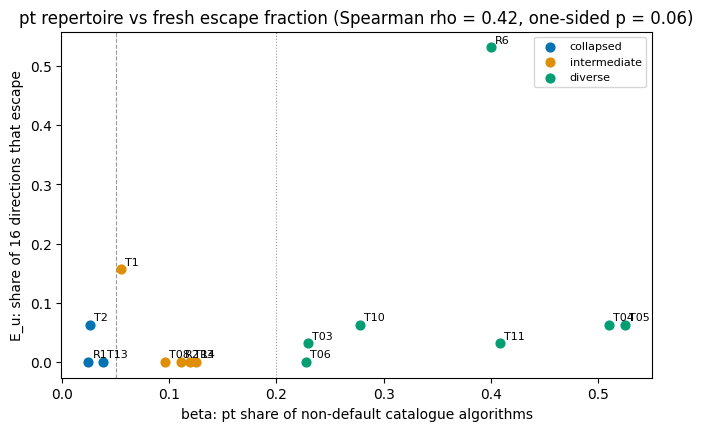

f1 ok


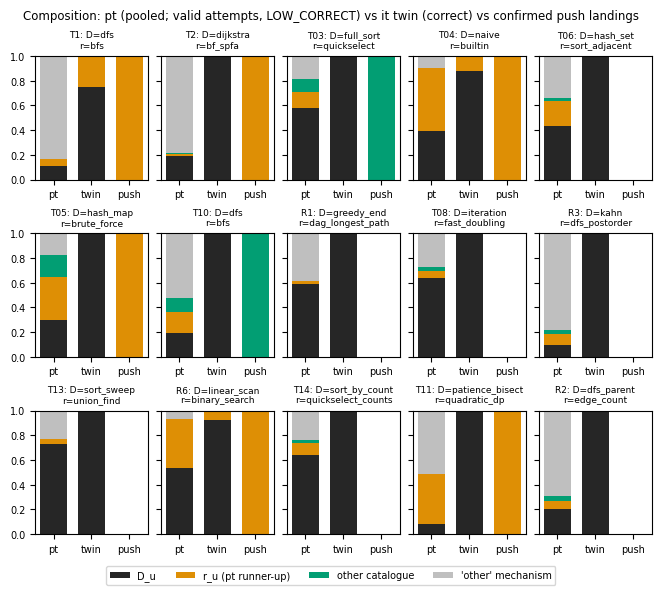

f2 ok


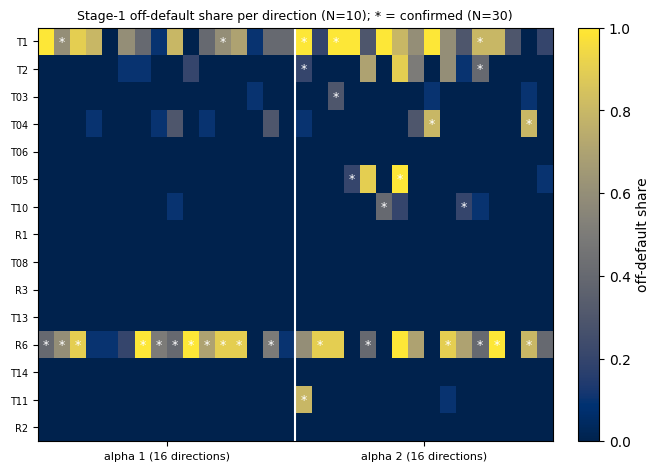

f3 ok


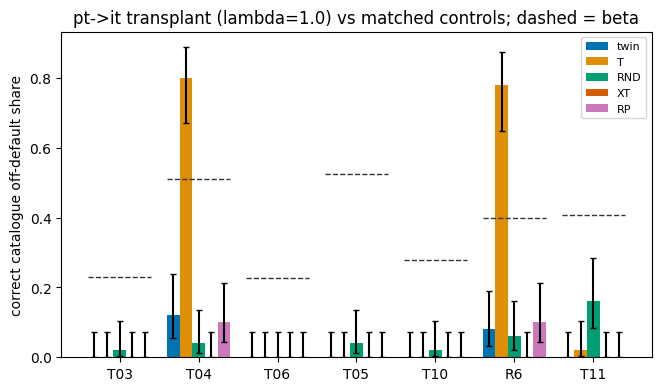

f4 ok


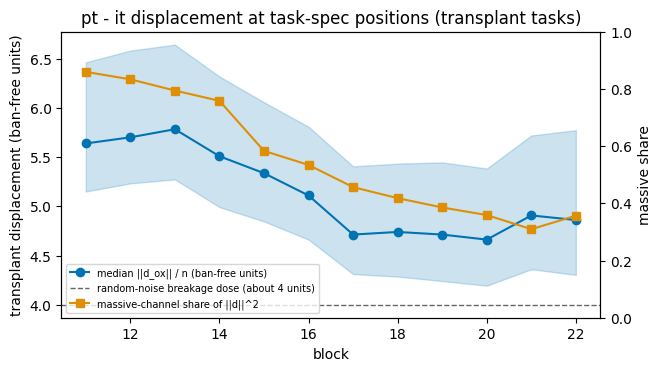

f5 ok


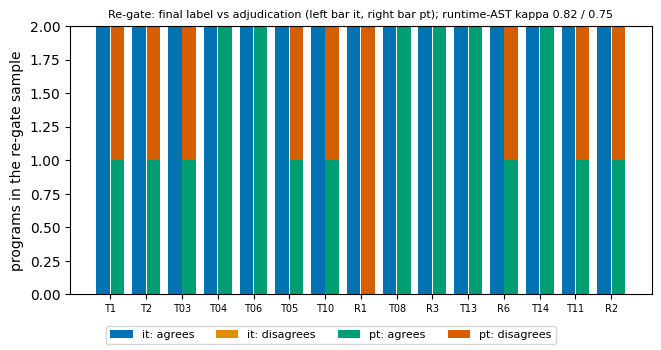

f6 ok


In [40]:
setup_logging("figures")
c1 = read_json(PRED_DIR / "commit_E1.json")
esc = read_json(RESULTS_DIR / "escape.json")
a1 = read_json(RESULTS_DIR / "e_a1.json")
tp = read_json(RESULTS_DIR / "transplant.json") if (RESULTS_DIR / "transplant.json").exists() else None
norms = META.get("transplant_norms")  # original: results/transplant_norms.json (needs the GPU activation cache)
reg = META.get("regate")  # original: results/regate.json (re-gate sample, two OpenRouter judge families)
for fn, args in ((f1, (c1, a1, esc)), (f2, (c1, esc)), (f3, (c1, esc)), (f4, (tp,)), (f5, (norms,)), (f6, (reg,))):
    try:
        fn(*args)
        print(f"{fn.__name__} ok")
    except Exception as e:  # noqa: BLE001 - one failing figure must not block the others
        import traceback

        traceback.print_exc()
        print(f"{fn.__name__} failed: {e}")

## Takeaways

* **E-A2 passes; E-A1 is inconclusive.** Where a nudge lands is predicted well by the base model's runner-up (5/7 hits,
  +1.50 nats/event over the association forecast). *Whether* a task moves is predicted only weakly (rho = 0.42,
  p = 0.06). beta_u is not ahead of the simplest rivals: the twin modal share (rho 0.67) and the novelty instruction
  (rho 0.64) both correlate better with E_u.
* **Transplanting the pt state is not sufficient in general.** It moves exactly the two tasks whose it twin already
  writes the runner-up 8–12% of the time: T04 (naive → builtin, 40/50) and R6 (linear scan → binary search,
  39/50). The other five base-diverse tasks stay at their default. The RP control and the base-collapsed controls
  are inert. RND and XT at matched norm break programs, so the pre-registered norm-confound rule applies.
* **Novelty.** None of the 56 correct "other" programs is a new algorithm (rule-of-three 95% bound 0.054). They come
  from the novelty instruction, pt, pushes and transplants. The interventions re-rank known algorithms; they do not
  invent new ones.
* **Caveats:**
  * n = 15 units gives low power.
  * The pt labels are weak: pt-chat output is 91% unusable and judge agreement on pt programs is 0.64.
  * The controls broke validity.
  * These are seen tasks (a replication, not a confirmation).